<a href="https://colab.research.google.com/github/samyakjain31773-debug/-Amazon-Product-Analytics-ML-Intelligence/blob/main/Loan_Default_Risk_Prediction_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn

# Utilities
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)


All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
Scikit-learn version: 1.6.1


In [3]:
from  google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [5]:
import io
df = pd.read_csv(io.BytesIO(uploaded['train.csv']))
print("Data loaded successfully!")
print("Dataset shape:",df.shape)
display(df.head())

Data loaded successfully!
Dataset shape: (104805, 12)


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
1,2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
2,3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
3,4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
4,5,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0


In [14]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Column names
print("\n Column names:")
print(df.columns .tolist())

# Target distribution
print("\n Target Distribution:")
print(df['SeriousDlqin2yrs'].value_counts())

print("\n Target Percentage:")
print(
    df['SeriousDlqin2yrs']
    .value_counts(normalize=True) * 100
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104805 entries, 0 to 104804
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Id                                    104805 non-null  int64  
 1   SeriousDlqin2yrs                      104805 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  104805 non-null  float64
 3   age                                   104805 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  104805 non-null  int64  
 5   DebtRatio                             104805 non-null  float64
 6   MonthlyIncome                         84024 non-null   float64
 7   NumberOfOpenCreditLinesAndLoans       104805 non-null  int64  
 8   NumberOfTimes90DaysLate               104805 non-null  int64  
 9   NumberRealEstateLoansOrLines          104805 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  104805 non-null  int64  
 11  

,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,104805.000000,104805.000000,104805.000000,104805.000000,104805.000000,104805.000000,8.402400e+04,104805.000000,104805.000000,104805.000000,104805.000000,102056.000000
mean,75013.710863,0.066314,5.602014,52.351128,0.416077,354.859470,6.684453e+03,8.454854,0.259988,1.019551,0.235571,0.756065
std,43324.043054,0.248831,217.389876,14.765944,4.139291,2169.182855,1.565313e+04,5.127986,4.115594,1.136847,4.101263,1.112162
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37508.000000,0.000000,0.029801,41.000000,0.000000,0.175026,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,74931.000000,0.000000,0.153984,52.000000,0.000000,0.366626,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112620.000000,0.000000,0.559168,63.000000,0.000000,0.867267,8.250000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,149999.000000,1.000000,29110.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,13.000000



 Column names:
['Id', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

 Target Distribution:
SeriousDlqin2yrs
0    97855
1     6950
Name: count, dtype: int64

 Target Percentage:
SeriousDlqin2yrs
0    93.368637
1     6.631363
Name: proportion, dtype: float64


In [13]:
# 1. Missing values
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage':(df.isnull().mean() * 100).round(2)
})
print("Missing Values Analysis:")
display(
        missing.sort_values(
         by='Missing_Percentage',
         ascending=False
))

# 2. Duplicate records
print("Duplicate roes:", df.duplicated().sum())

# 3. Duplicate IDs
print("Duplicate IDs:", df['Id'].duplicated().sum())

# 4. Unique target values
print("Target Values:", df['SeriousDlqin2yrs'].unique())




Missing Values Analysis:


,Missing_Count,Missing_Percentage
MonthlyIncome,20781,19.83
NumberOfDependents,2749,2.62
Id,0,0.00
SeriousDlqin2yrs,0,0.00
age,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
DebtRatio,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
NumberOfOpenCreditLinesAndLoans,0,0.00
NumberOfTimes90DaysLate,0,0.00


Duplicate roes: 0
Duplicate IDs: 0
Target Values: [0 1]


In [16]:
target_counts = df['SeriousDlqin2yrs'].value_counts()

print("Non-Default Customers:", target_counts[0])
print("Default Customers:", target_counts[1])

print("\nClass Percentage:")
print((df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100).round(2))

Non-Default Customers: 97855
Default Customers: 6950

Class Percentage:
SeriousDlqin2yrs
0    93.37
1     6.63
Name: proportion, dtype: float64


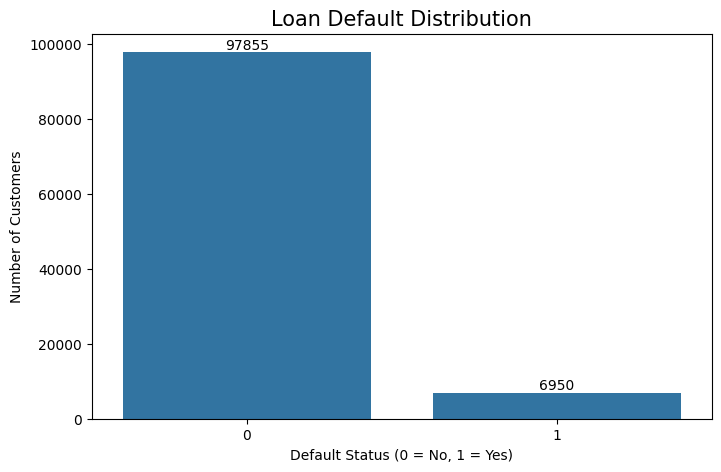

In [17]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x= 'SeriousDlqin2yrs')
plt.title('Loan Default Distribution',fontsize=15)
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)
plt.show()


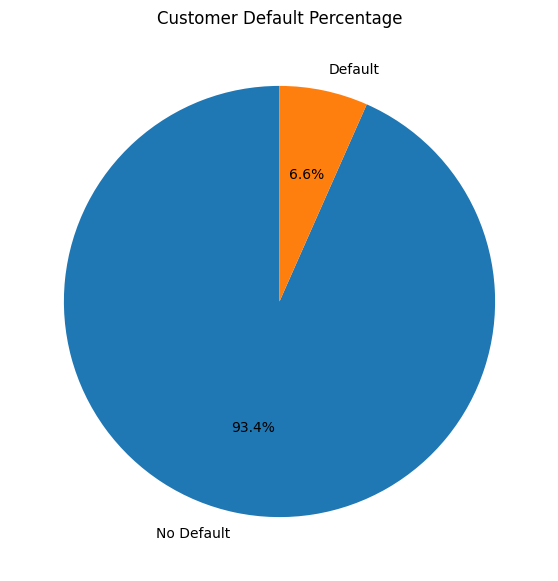

In [18]:
plt.figure(figsize=(7,7))

plt.pie(
    df['SeriousDlqin2yrs'].value_counts(),
    labels=['No Default', 'Default'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Default Percentage')
plt.show()

In [19]:

print("Total records:", len(df))
print("Minimum ID:", df['Id'].min())
print("Maximum ID:", df['Id'].max())

print(
    "Missing IDs within ID range:",
    df['Id'].max() - df['Id'].min() + 1 - df['Id'].nunique()
)


Total records: 104805
Minimum ID: 1
Maximum ID: 149999
Missing IDs within ID range: 45194


In [20]:

# Sort IDs
sorted_ids = df['Id'].sort_values()

# Calculate gaps between consecutive IDs
id_gaps = sorted_ids.diff()

print("ID Gap Analysis:")
print(id_gaps.value_counts().head(10))

print("\nLargest ID gaps:")
print(
    sorted_ids.diff()
    .sort_values(ascending=False)
    .head(10)
)


ID Gap Analysis:
Id
1.0     73216
2.0     22127
3.0      6593
4.0      1976
5.0       626
6.0       183
7.0        52
8.0        27
9.0         3
10.0        1
Name: count, dtype: int64

Largest ID gaps:
51659    10.0
68246     9.0
76538     9.0
59936     9.0
13901     8.0
41201     8.0
40427     8.0
35077     8.0
4685      8.0
42978     8.0
Name: Id, dtype: float64


In [21]:

# Divide IDs into 10 ranges
df['ID_Range'] = pd.cut(
    df['Id'],
    bins=10
)

print("Records in each ID range:")
display(df['ID_Range'].value_counts().sort_index())


Records in each ID range:


,count
ID_Range,
"(-148.998, 15000.8]",10498
"(15000.8, 30000.6]",10443
"(30000.6, 45000.4]",10512
"(45000.4, 60000.2]",10500
"(60000.2, 75000.0]",10496
"(75000.0, 89999.8]",10453
"(89999.8, 104999.6]",10408
"(104999.6, 119999.4]",10435
"(119999.4, 134999.2]",10528


In [22]:

id_analysis = df.groupby(
    'ID_Range',
    observed=False
)['SeriousDlqin2yrs'].agg(
    Total_Customers='count',
    Default_Count='sum',
    Default_Rate='mean'
)

id_analysis['Default_Rate'] *= 100

display(id_analysis.round(2))


,Total_Customers,Default_Count,Default_Rate
ID_Range,,,
"(-148.998, 15000.8]",10498,669,6.37
"(15000.8, 30000.6]",10443,673,6.44
"(30000.6, 45000.4]",10512,766,7.29
"(45000.4, 60000.2]",10500,683,6.50
"(60000.2, 75000.0]",10496,672,6.40
"(75000.0, 89999.8]",10453,662,6.33
"(89999.8, 104999.6]",10408,703,6.75
"(104999.6, 119999.4]",10435,679,6.51
"(119999.4, 134999.2]",10528,694,6.59


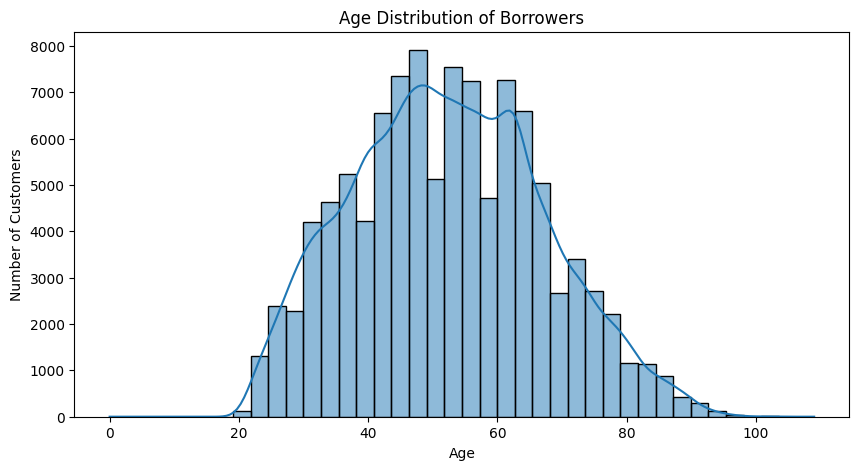

In [23]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='age',
    bins=40,
    kde=True
)

plt.title('Age Distribution of Borrowers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()


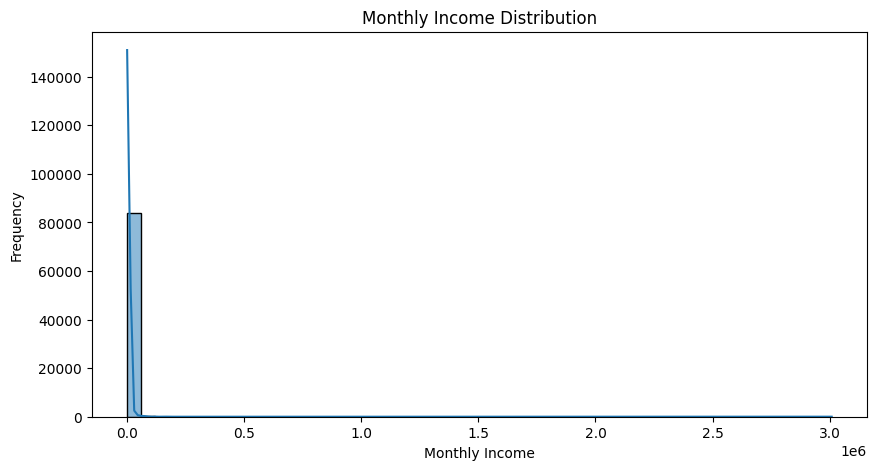

In [24]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='MonthlyIncome',
    bins=50,
    kde=True
)

plt.title('Monthly Income Distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Frequency')

plt.show()


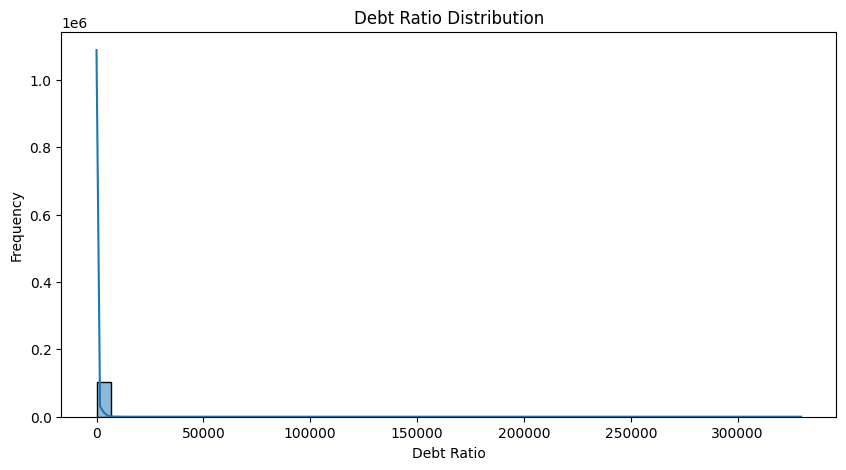

In [25]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='DebtRatio',
    bins=50,
    kde=True
)

plt.title('Debt Ratio Distribution')
plt.xlabel('Debt Ratio')
plt.ylabel('Frequency')

plt.show()


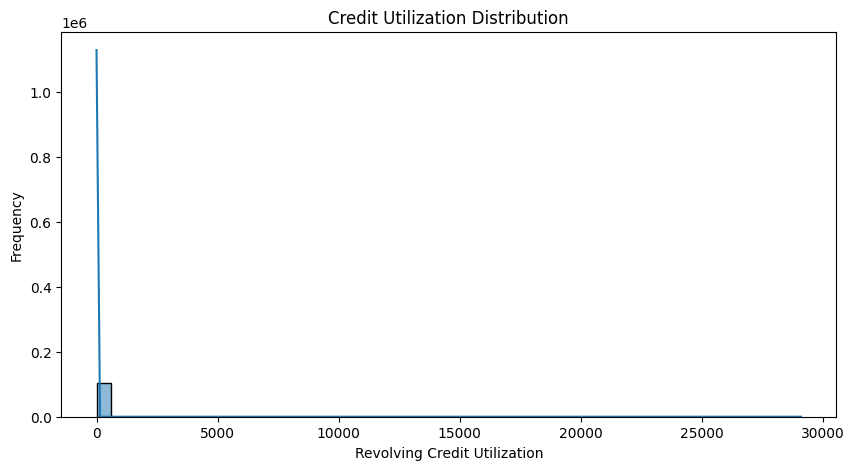

In [26]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='RevolvingUtilizationOfUnsecuredLines',
    bins=50,
    kde=True
)

plt.title('Credit Utilization Distribution')
plt.xlabel('Revolving Credit Utilization')
plt.ylabel('Frequency')

plt.show()


In [27]:

features = [
    'age',
    'MonthlyIncome',
    'DebtRatio',
    'RevolvingUtilizationOfUnsecuredLines'
]

for feature in features:

    print("\nFeature:", feature)

    print(df[feature].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    ))



Feature: age
count    104805.000000
mean         52.351128
std          14.765944
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
90%          72.000000
95%          78.000000
99%          87.000000
max         109.000000
Name: age, dtype: float64

Feature: MonthlyIncome
count    8.402400e+04
mean     6.684453e+03
std      1.565313e+04
min      0.000000e+00
25%      3.400000e+03
50%      5.400000e+03
75%      8.250000e+03
90%      1.166600e+04
95%      1.468970e+04
99%      2.500000e+04
max      3.008750e+06
Name: MonthlyIncome, dtype: float64

Feature: DebtRatio
count    104805.000000
mean        354.859470
std        2169.182855
min           0.000000
25%           0.175026
50%           0.366626
75%           0.867267
90%        1274.000000
95%        2458.800000
99%        5009.000000
max      329664.000000
Name: DebtRatio, dtype: float64

Feature: RevolvingUtilizationOfUnsecuredLines
count    104805.000000
mean          5.602014
std    

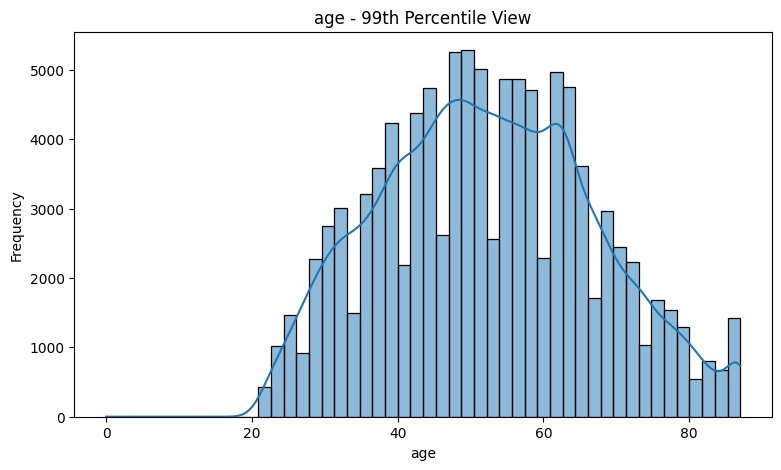

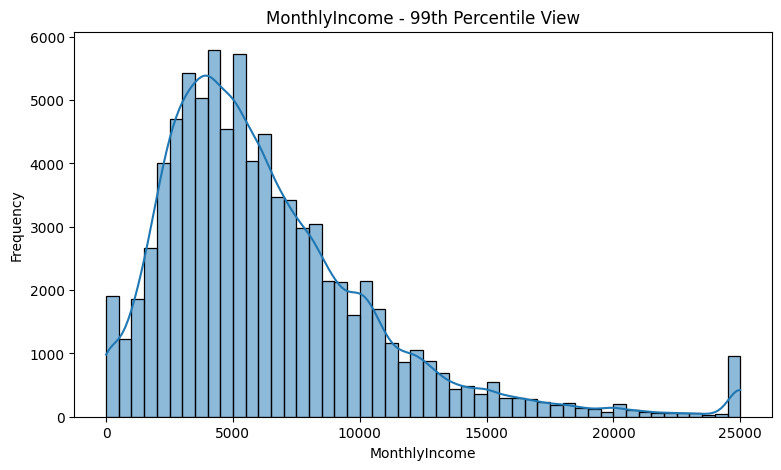

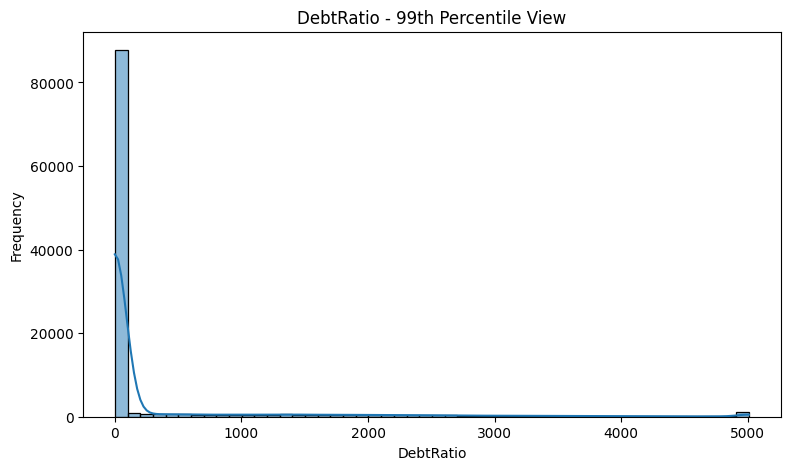

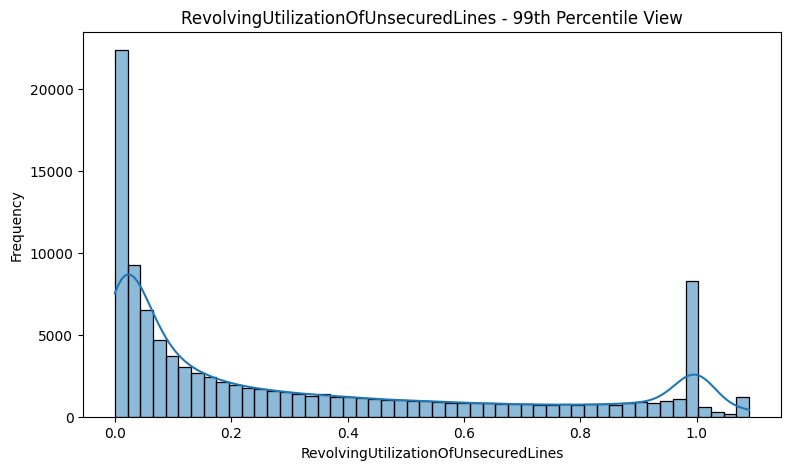

In [28]:

features = [
    'age',
    'MonthlyIncome',
    'DebtRatio',
    'RevolvingUtilizationOfUnsecuredLines'
]

for feature in features:

    upper_limit = df[feature].quantile(0.99)

    plt.figure(figsize=(9, 5))

    sns.histplot(
        df[feature].dropna().clip(upper=upper_limit),
        bins=50,
        kde=True
    )

    plt.title(f'{feature} - 99th Percentile View')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

    plt.show()


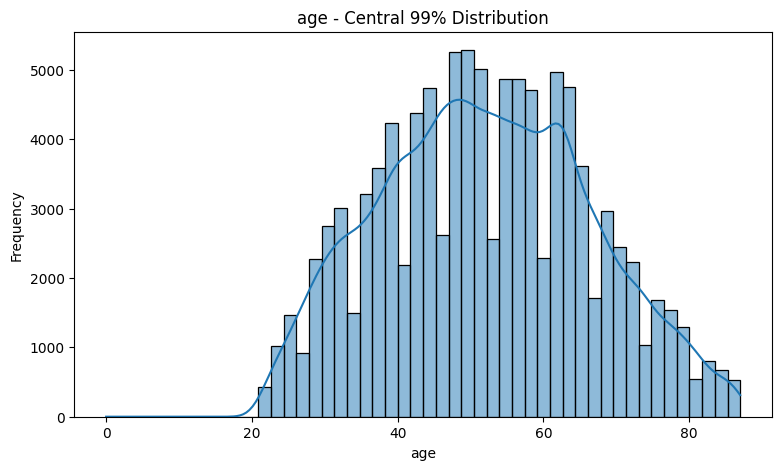

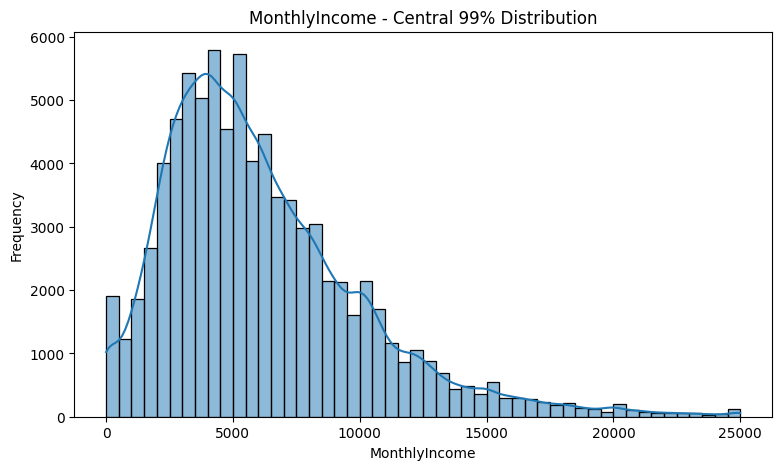

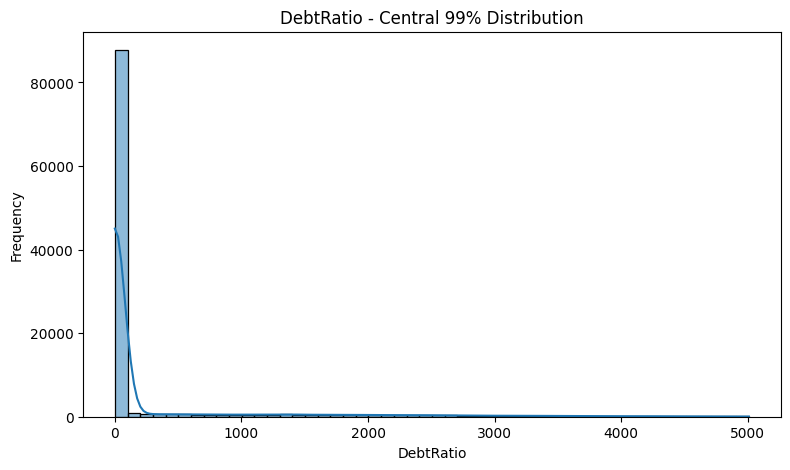

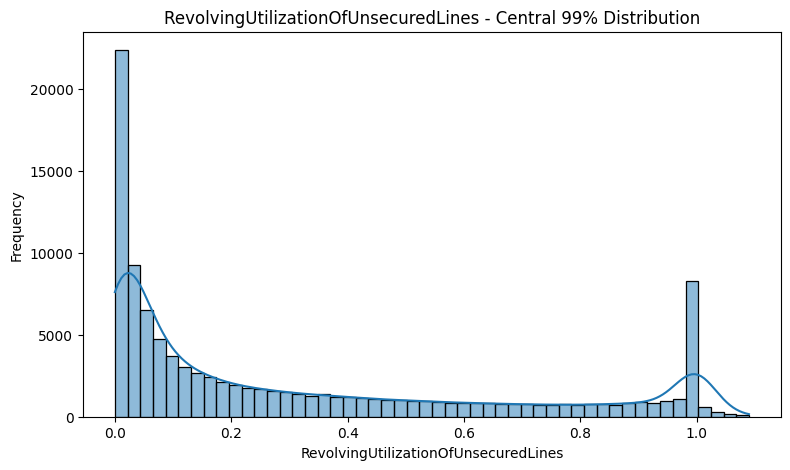

In [29]:

features = [
    'age',
    'MonthlyIncome',
    'DebtRatio',
    'RevolvingUtilizationOfUnsecuredLines'
]

for feature in features:

    upper_limit = df[feature].quantile(0.99)

    # Visualization only: exclude extreme upper 1%
    plot_data = df.loc[
        df[feature] <= upper_limit,
        feature
    ].dropna()

    plt.figure(figsize=(9, 5))

    sns.histplot(
        plot_data,
        bins=50,
        kde=True
    )

    plt.title(f'{feature} - Central 99% Distribution')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

    plt.show()


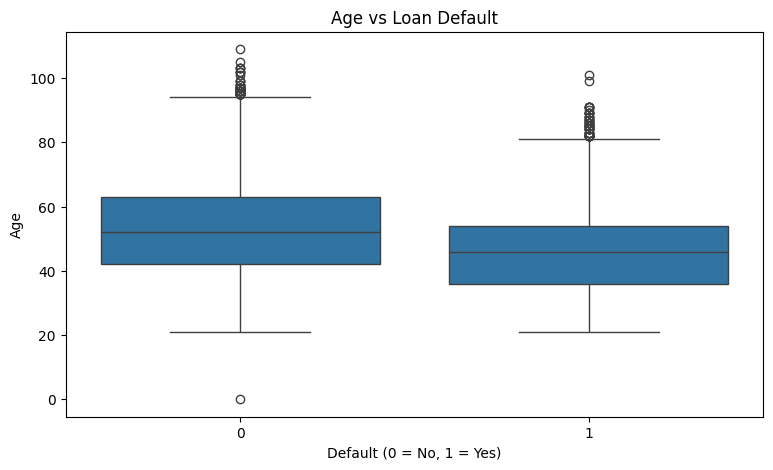

In [30]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='SeriousDlqin2yrs',
    y='age'
)

plt.title('Age vs Loan Default')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Age')

plt.show()


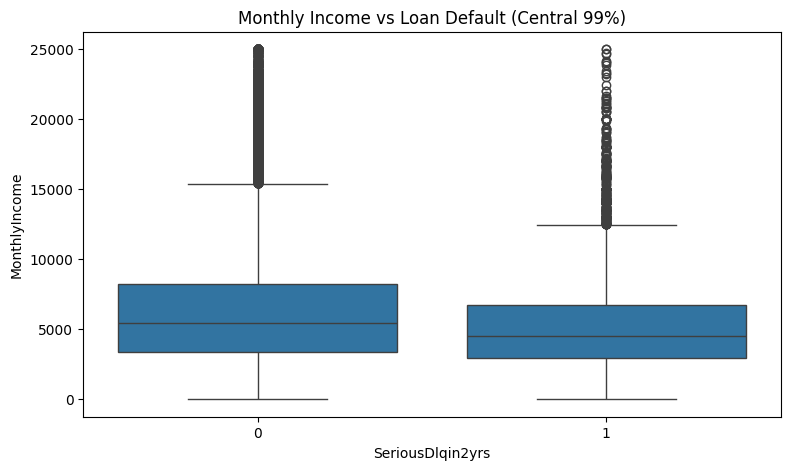

In [31]:

income_limit = df['MonthlyIncome'].quantile(0.99)

income_plot = df[
    df['MonthlyIncome'] <= income_limit
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=income_plot,
    x='SeriousDlqin2yrs',
    y='MonthlyIncome'
)

plt.title('Monthly Income vs Loan Default (Central 99%)')
plt.show()


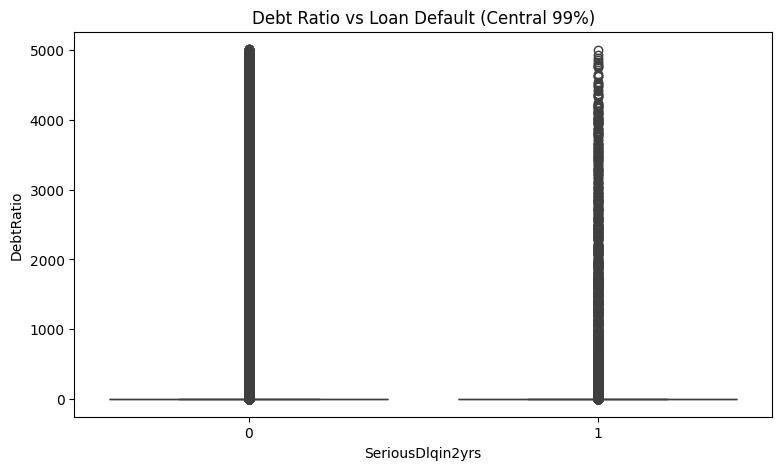

In [32]:

debt_limit = df['DebtRatio'].quantile(0.99)

debt_plot = df[
    df['DebtRatio'] <= debt_limit
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=debt_plot,
    x='SeriousDlqin2yrs',
    y='DebtRatio'
)

plt.title('Debt Ratio vs Loan Default (Central 99%)')
plt.show()


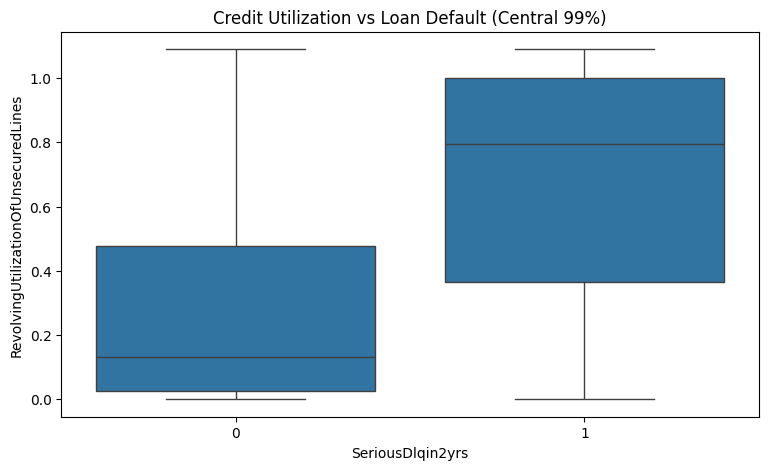

In [33]:

util_limit = df[
    'RevolvingUtilizationOfUnsecuredLines'
].quantile(0.99)

util_plot = df[
    df['RevolvingUtilizationOfUnsecuredLines'] <= util_limit
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=util_plot,
    x='SeriousDlqin2yrs',
    y='RevolvingUtilizationOfUnsecuredLines'
)

plt.title('Credit Utilization vs Loan Default (Central 99%)')
plt.show()


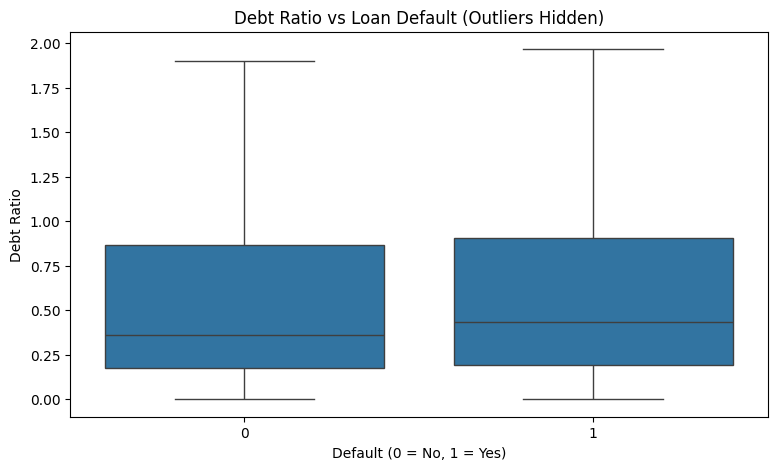

In [34]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='SeriousDlqin2yrs',
    y='DebtRatio',
    showfliers=False
)

plt.title('Debt Ratio vs Loan Default (Outliers Hidden)')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Debt Ratio')

plt.show()


In [35]:

features = [
    'age',
    'MonthlyIncome',
    'DebtRatio',
    'RevolvingUtilizationOfUnsecuredLines'
]

group_comparison = df.groupby('SeriousDlqin2yrs')[features].agg(
    ['mean', 'median', 'min', 'max']
)

display(group_comparison.round(3))


age                 MonthlyIncome               \
                    mean median min  max          mean  median  min   
SeriousDlqin2yrs                                                      
0                 52.808   52.0   0  109      6763.395  5461.0  0.0   
1                 45.914   46.0  21  101      5616.206  4500.0  0.0   

                            DebtRatio                        \
                        max      mean median  min       max   
SeriousDlqin2yrs                                              
0                 3008750.0   359.613  0.363  0.0  329664.0   
1                  250000.0   287.933  0.431  0.0   24466.0   

                 RevolvingUtilizationOfUnsecuredLines                       
                                                 mean median  min      max  
SeriousDlqin2yrs                                                            
0                                               5.696  0.133  0.0  29110.0  
1                                               4.279  0.834  0.0   8328.0

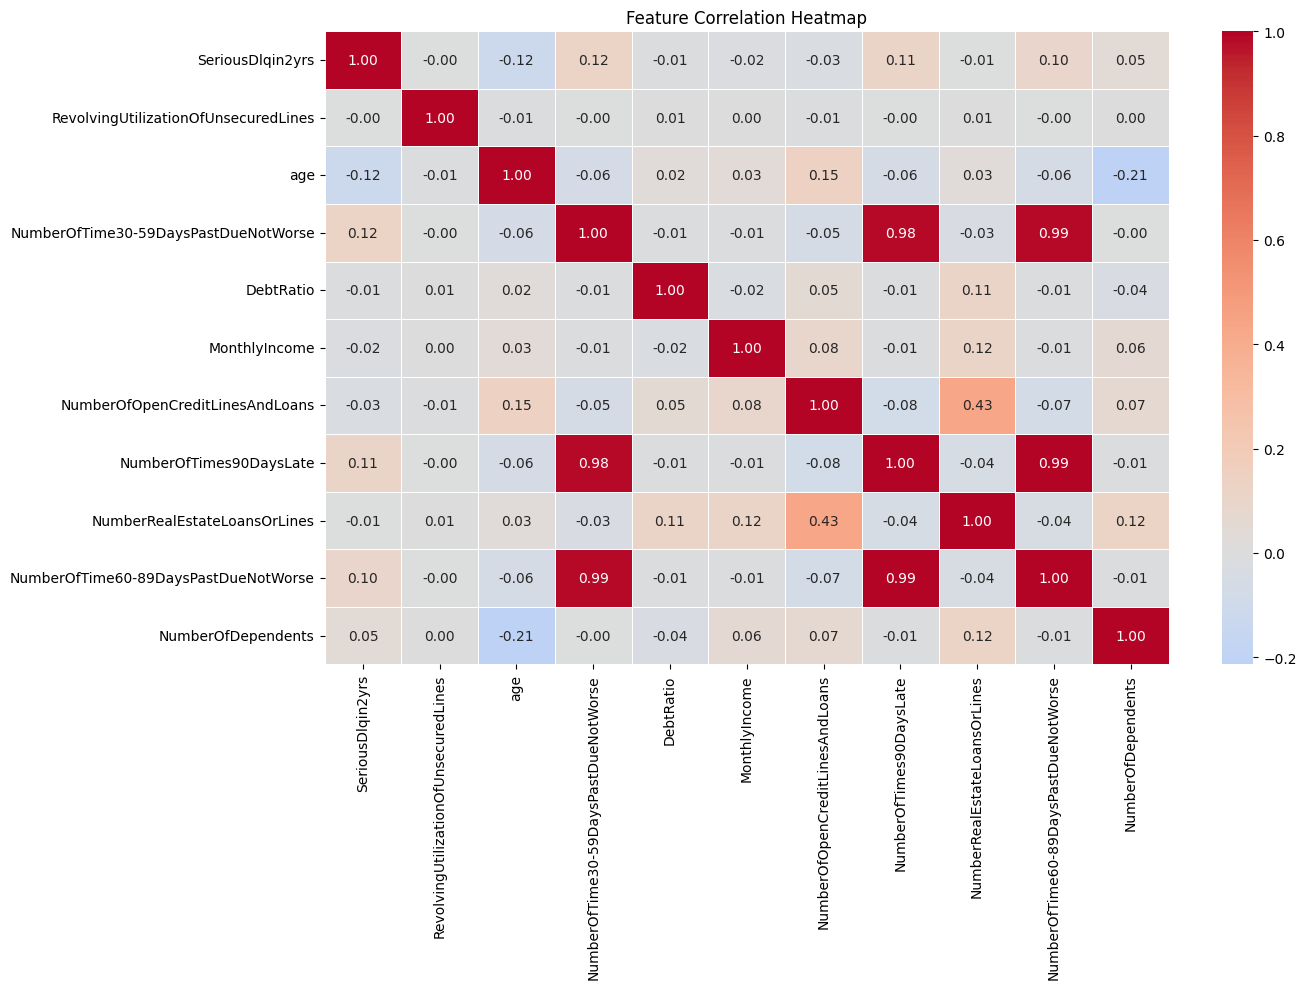

In [36]:

# Remove ID_Range if it exists
corr_df = df.drop(
    columns=['Id', 'ID_Range'],
    errors='ignore'
)

# Calculate correlation
correlation = corr_df.corr(method='pearson')

# Visualize correlation
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [38]:

# STEP 1: Prepare correlation dataset

corr_df = df.drop(
    columns=['Id', 'ID_Range'],
    errors='ignore'
)

# STEP 2: Calculate Pearson correlation
pearson_corr = corr_df.corr(method='pearson')

# STEP 3: Calculate Spearman correlation
spearman_corr = corr_df.corr(method='spearman')

# STEP 4: Extract target correlations
target = 'SeriousDlqin2yrs'

print("PEARSON CORRELATION WITH LOAN DEFAULT")

pearson_target = pearson_corr[target].drop(target)

display(
    pearson_target.sort_values(
        ascending=False
    ).to_frame(name='Pearson_Correlation')
)

print("\nSPEARMAN CORRELATION WITH LOAN DEFAULT")

spearman_target = spearman_corr[target].drop(target)

display(
    spearman_target.sort_values(
        ascending=False
    ).to_frame(name='Spearman_Correlation')
)


PEARSON CORRELATION WITH LOAN DEFAULT


,Pearson_Correlation
NumberOfTime30-59DaysPastDueNotWorse,0.121637
NumberOfTimes90DaysLate,0.113056
NumberOfTime60-89DaysPastDueNotWorse,0.098301
NumberOfDependents,0.045753
RevolvingUtilizationOfUnsecuredLines,-0.001622
NumberRealEstateLoansOrLines,-0.005224
DebtRatio,-0.008223
MonthlyIncome,-0.018552
NumberOfOpenCreditLinesAndLoans,-0.026578
age,-0.116189



SPEARMAN CORRELATION WITH LOAN DEFAULT


,Spearman_Correlation
NumberOfTimes90DaysLate,0.339742
NumberOfTime60-89DaysPastDueNotWorse,0.275086
NumberOfTime30-59DaysPastDueNotWorse,0.252720
RevolvingUtilizationOfUnsecuredLines,0.240905
NumberOfDependents,0.044791
DebtRatio,0.022435
NumberRealEstateLoansOrLines,-0.032366
NumberOfOpenCreditLinesAndLoans,-0.035037
MonthlyIncome,-0.065991
age,-0.117655


In [39]:

late_features = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

for col in late_features:

    print(f"\nFeature: {col}")

    print(
        df[col].value_counts()
        .sort_index()
        .tail(15)
    )



Feature: NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
0     88076
1     11171
2      3229
3      1218
4       534
5       232
6        90
7        43
8        17
9         6
10        3
12        2
13        1
96        2
98      181
Name: count, dtype: int64

Feature: NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
0     99527
1      3982
2       770
3       217
4        81
5        24
6        11
7         8
9         1
11        1
96        2
98      181
Name: count, dtype: int64

Feature: NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
4     202
5      89
6      56
7      27
8      12
9      14
10      6
11      4
12      2
13      2
14      2
15      2
17      1
96      2
98    181
Name: count, dtype: int64


In [40]:

print("Age = 0 records:")
display(df[df['age'] == 0])

print("\nAge below 18:")
display(df[df['age'] < 18])

print("\nAge above 100:")
display(df[df['age'] > 100])


Age = 0 records:


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,ID_Range
45915,65695,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0,"(60000.2, 75000.0]"



Age below 18:


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,ID_Range
45915,65695,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0,"(60000.2, 75000.0]"



Age above 100:


,Id,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,ID_Range
5397,7763,0,0.069167,101,0,50.000000,NaN,2,0,0,0,0.0,"(-148.998, 15000.8]"
13931,19884,0,1.000000,103,0,0.000000,1600.0,3,0,0,0,0.0,"(15000.8, 30000.6]"
17855,25561,0,0.009866,102,0,0.002424,3300.0,3,0,0,0,0.0,"(15000.8, 30000.6]"
39642,56761,0,0.003469,105,0,2.000000,NaN,4,0,0,0,NaN,"(45000.4, 60000.2]"
40488,57967,0,0.001397,103,0,1798.500000,1.0,11,0,2,0,0.0,"(45000.4, 60000.2]"
63555,90937,0,0.000000,102,0,0.000000,NaN,12,0,0,0,0.0,"(89999.8, 104999.6]"
67413,96450,0,0.109642,102,0,0.273844,3417.0,7,0,0,0,1.0,"(89999.8, 104999.6]"
81045,116129,1,0.002964,101,2,0.001387,2883.0,6,0,0,0,0.0,"(104999.6, 119999.4]"
94295,135025,0,0.004059,103,0,5.000000,NaN,6,0,0,0,0.0,"(134999.2, 149999.0]"
96590,138291,0,0.246529,109,0,318.000000,NaN,3,0,0,0,NaN,"(134999.2, 149999.0]"


In [41]:

col = 'RevolvingUtilizationOfUnsecuredLines'

print("Values above 1:")
print((df[col] > 1).sum())

print("\nValues above 10:")
print((df[col] > 10).sum())

print("\nTop 10 highest values:")
display(
    df.nlargest(10, col)[
        [col, 'SeriousDlqin2yrs']
    ]
)


Values above 1:
2337

Values above 10:
156

Top 10 highest values:


,RevolvingUtilizationOfUnsecuredLines,SeriousDlqin2yrs
21937,29110.0,0
11857,22198.0,0
104289,20514.0,0
81864,18300.0,0
15365,17441.0,0
86947,13930.0,0
50791,13498.0,0
41120,11843.0,0
58074,11553.0,0
85915,10151.0,0


In [42]:

late_features = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

# Count special values
for col in late_features:
    print(f"\n{col}")
    print("Value 96:", (df[col] == 96).sum())
    print("Value 98:", (df[col] == 98).sum())

# Check records where any late-payment feature is 96 or 98
special_mask = df[late_features].isin([96, 98]).any(axis=1)

print("\nTotal records with special values:", special_mask.sum())

display(
    df.loc[
        special_mask,
        late_features + ['SeriousDlqin2yrs']
    ].head(20)
)



NumberOfTime30-59DaysPastDueNotWorse
Value 96: 2
Value 98: 181

NumberOfTime60-89DaysPastDueNotWorse
Value 96: 2
Value 98: 181

NumberOfTimes90DaysLate
Value 96: 2
Value 98: 181

Total records with special values: 183


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,SeriousDlqin2yrs
1187,98,98,98,1
1556,98,98,98,0
2674,98,98,98,0
3064,98,98,98,0
3525,98,98,98,0
4371,98,98,98,1
4881,98,98,98,1
5346,98,98,98,1
6468,98,98,98,0
6740,98,98,98,1


In [43]:

for col in late_features:

    print(f"\nDefault rate by {col}")

    result = df.groupby(col)['SeriousDlqin2yrs'].agg(
        Customers='count',
        Defaults='sum',
        Default_Rate='mean'
    )

    result['Default_Rate'] *= 100

    display(result.round(2))



Default rate by NumberOfTime30-59DaysPastDueNotWorse


,Customers,Defaults,Default_Rate
NumberOfTime30-59DaysPastDueNotWorse,,,
0,88076,3533,4.01
1,11171,1639,14.67
2,3229,841,26.05
3,1218,419,34.40
4,534,225,42.13
5,232,111,47.84
6,90,49,54.44
7,43,24,55.81
8,17,6,35.29



Default rate by NumberOfTime60-89DaysPastDueNotWorse


,Customers,Defaults,Default_Rate
NumberOfTime60-89DaysPastDueNotWorse,,,
0,99527,5042,5.07
1,3982,1222,30.69
2,770,383,49.74
3,217,125,57.60
4,81,52,64.20
5,24,16,66.67
6,11,8,72.73
7,8,5,62.50
9,1,0,0.00



Default rate by NumberOfTimes90DaysLate


,Customers,Defaults,Default_Rate
NumberOfTimes90DaysLate,,,
0,99089,4575,4.62
1,3605,1211,33.59
2,1043,522,50.05
3,466,267,57.30
4,202,134,66.34
5,89,60,67.42
6,56,33,58.93
7,27,22,81.48
8,12,9,75.00


In [44]:
# Check how 96 and 98 are distributed across all three columns

late_features = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

special_mask = df[late_features].isin([96, 98])

print("Special-value count in each column:")
display(special_mask.sum())

print("Rows with special values in at least one column:",
      special_mask.any(axis=1).sum())

print("Rows with special values in all three columns:",
      special_mask.all(axis=1).sum())

print("\nCombination of special values:")
display(
    df.loc[special_mask.any(axis=1), late_features]
      .value_counts()
      .rename("Customers")
      .reset_index()
)

Special-value count in each column:


,0
NumberOfTime30-59DaysPastDueNotWorse,183
NumberOfTime60-89DaysPastDueNotWorse,183
NumberOfTimes90DaysLate,183


Rows with special values in at least one column: 183
Rows with special values in all three columns: 183

Combination of special values:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,Customers
0,98,98,98,181
1,96,96,96,2


In [45]:
print("DebtRatio above 1:", (df['DebtRatio'] > 1).sum())
print("DebtRatio above 10:", (df['DebtRatio'] > 10).sum())
print("DebtRatio above 100:", (df['DebtRatio'] > 100).sum())

print("\nDebtRatio percentiles:")
display(
    df['DebtRatio'].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
    )
)

print("\nTop 10 DebtRatio records:")
display(
    df.nlargest(10, 'DebtRatio')[
        ['Id', 'DebtRatio', 'MonthlyIncome', 'SeriousDlqin2yrs']
    ]
)

DebtRatio above 1: 24549
DebtRatio above 10: 20209
DebtRatio above 100: 17065

DebtRatio percentiles:


,DebtRatio
0.500,0.366626
0.750,0.867267
0.900,1274.000000
0.950,2458.800000
0.990,5009.000000
0.995,6218.960000
0.999,10736.820000
1.000,329664.000000



Top 10 DebtRatio records:


,Id,DebtRatio,MonthlyIncome,SeriousDlqin2yrs
42063,60152,329664.0,NaN,0
25576,36600,326442.0,NaN,0
88704,127047,307001.0,NaN,0
3371,4854,168835.0,NaN,0
48831,69845,101320.0,NaN,0
46668,66785,61907.0,NaN,0
37525,53682,61106.5,1.0,0
89310,127898,60212.0,0.0,0
32212,46102,52112.0,NaN,0
102219,146310,49112.0,0.0,0


In [46]:
import numpy as np
import pandas as pd

df['Income_Status'] = np.select(
    [
        df['MonthlyIncome'].isna(),
        df['MonthlyIncome'].eq(0),
        df['MonthlyIncome'].gt(0)
    ],
    [
        'Missing Income',
        'Zero Income',
        'Positive Income'
    ],
    default='Other'
)

income_summary = df.groupby('Income_Status').agg(
    Customers=('Id', 'count'),
    Average_DebtRatio=('DebtRatio', 'mean'),
    Median_DebtRatio=('DebtRatio', 'median'),
    Maximum_DebtRatio=('DebtRatio', 'max')
)

display(income_summary.round(2))

,Customers,Average_DebtRatio,Median_DebtRatio,Maximum_DebtRatio
Income_Status,,,,
Missing Income,20781,1679.69,1164.00,329664.0
Positive Income,82878,5.72,0.29,61106.5
Zero Income,1146,1580.72,913.00,60212.0


In [47]:
debt_percentiles = (
    df.groupby('Income_Status')['DebtRatio']
      .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
      .unstack()
)

display(debt_percentiles.round(2))

,0.50,0.75,0.90,0.95,0.99,1.00
Income_Status,,,,,,
Missing Income,1164.00,2391.00,3779.00,4931.00,8107.00,329664.0
Positive Income,0.29,0.47,0.72,0.98,3.00,61106.5
Zero Income,913.00,2184.75,3579.50,4851.25,9890.95,60212.0


In [48]:
extreme_debt = df[df['DebtRatio'] > 100]

print("Total records with DebtRatio > 100:",
      len(extreme_debt))

print("\nIncome status distribution:")
display(extreme_debt['Income_Status'].value_counts())

print("\nDefault rate among extreme DebtRatio records:")
display(
    extreme_debt.groupby('Income_Status')['SeriousDlqin2yrs']
    .agg(Customers='count', Defaults='sum', Default_Rate='mean')
    .assign(Default_Rate=lambda x: x['Default_Rate'] * 100)
    .round(2)
)

Total records with DebtRatio > 100: 17065

Income status distribution:


,count
Income_Status,
Missing Income,15872
Zero Income,855
Positive Income,338



Default rate among extreme DebtRatio records:


,Customers,Defaults,Default_Rate
Income_Status,,,
Missing Income,15872,937,5.90
Positive Income,338,7,2.07
Zero Income,855,37,4.33


In [49]:
# Default rate by income status

income_default_analysis = df.groupby('Income_Status').agg(
    Customers=('SeriousDlqin2yrs', 'size'),
    Defaults=('SeriousDlqin2yrs', 'sum'),
    Default_Rate=('SeriousDlqin2yrs', 'mean')
)

income_default_analysis['Default_Rate'] *= 100

display(income_default_analysis.round(2))

,Customers,Defaults,Default_Rate
Income_Status,,,
Missing Income,20781,1168,5.62
Positive Income,82878,5740,6.93
Zero Income,1146,42,3.66


In [50]:
# Income status distribution within each target class

income_target_distribution = pd.crosstab(
    df['SeriousDlqin2yrs'],
    df['Income_Status'],
    normalize='index'
) * 100

income_target_distribution.index = [
    'Non-Default (0)',
    'Default (1)'
]

display(income_target_distribution.round(2))

Income_Status,Missing Income,Positive Income,Zero Income
Non-Default (0),20.04,78.83,1.13
Default (1),16.81,82.59,0.60


In [51]:
# Monthly income comparison by target

income_by_target = df.groupby('SeriousDlqin2yrs')['MonthlyIncome'].agg(
    Customers='count',
    Mean_Income='mean',
    Median_Income='median',
    Min_Income='min',
    Max_Income='max'
)

display(income_by_target.round(2))

,Customers,Mean_Income,Median_Income,Min_Income,Max_Income
SeriousDlqin2yrs,,,,,
0,78242,6763.40,5461.0,0.0,3008750.0
1,5782,5616.21,4500.0,0.0,250000.0


In [52]:
# Income percentiles for each target group

income_percentiles = (
    df.groupby('SeriousDlqin2yrs')['MonthlyIncome']
      .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
      .unstack()
)

display(income_percentiles.round(2))

,0.25,0.50,0.75,0.90,0.95,0.99
SeriousDlqin2yrs,,,,,,
0,3440.00,5461.0,8333.00,11800.0,14863.7,25409.44
1,2989.75,4500.0,6814.25,10000.0,12500.0,21309.50


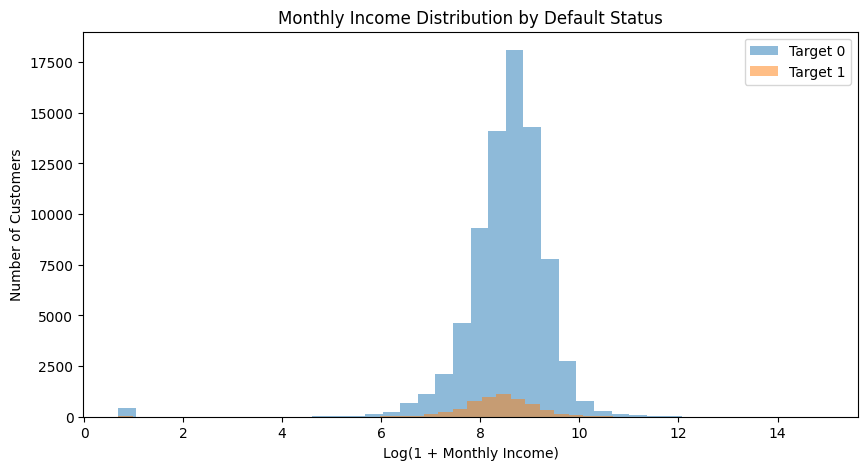

In [53]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

for target in [0, 1]:
    income = df.loc[
        (df['SeriousDlqin2yrs'] == target) &
        (df['MonthlyIncome'] > 0),
        'MonthlyIncome'
    ]

    plt.hist(
        np.log1p(income),
        bins=40,
        alpha=0.5,
        label=f'Target {target}'
    )

plt.title('Monthly Income Distribution by Default Status')
plt.xlabel('Log(1 + Monthly Income)')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

In [54]:
feature = 'NumberOfOpenCreditLinesAndLoans'

print("FEATURE:", feature)

print("\nBasic Statistics:")
display(df[feature].describe())

print("\nUnique Values:")
print("Total unique values:", df[feature].nunique())
print("Minimum:", df[feature].min())
print("Maximum:", df[feature].max())

print("\nValue Counts:")
display(df[feature].value_counts().sort_index())

FEATURE: NumberOfOpenCreditLinesAndLoans

Basic Statistics:


,NumberOfOpenCreditLinesAndLoans
count,104805.000000
mean,8.454854
std,5.127986
min,0.000000
25%,5.000000
50%,8.000000
75%,11.000000
max,58.000000



Unique Values:
Total unique values: 58
Minimum: 0
Maximum: 58

Value Counts:


,count
NumberOfOpenCreditLinesAndLoans,
0,1295
1,3112
2,4680
3,6264
4,8135
5,9038
6,9495
7,9199
8,8783


In [55]:
result = df.groupby(feature)['SeriousDlqin2yrs'].agg(
    Customers='count',
    Defaults='sum',
    Default_Rate='mean'
)

result['Default_Rate'] *= 100

display(result.round(2))

,Customers,Defaults,Default_Rate
NumberOfOpenCreditLinesAndLoans,,,
0,1295,320,24.71
1,3112,423,13.59
2,4680,434,9.27
3,6264,441,7.04
4,8135,509,6.26
5,9038,563,6.23
6,9495,508,5.35
7,9199,516,5.61
8,8783,424,4.83


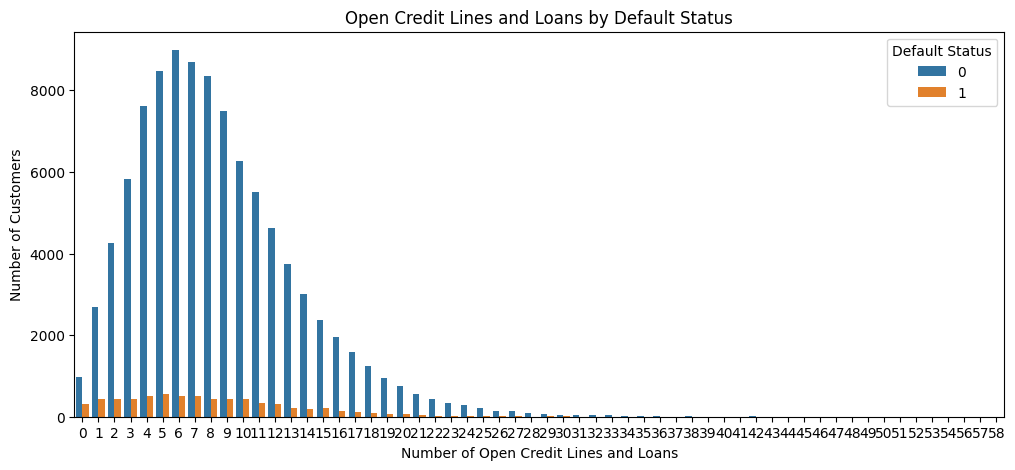

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x=feature,
    hue='SeriousDlqin2yrs'
)

plt.title('Open Credit Lines and Loans by Default Status')
plt.xlabel('Number of Open Credit Lines and Loans')
plt.ylabel('Number of Customers')
plt.legend(title='Default Status')
plt.show()

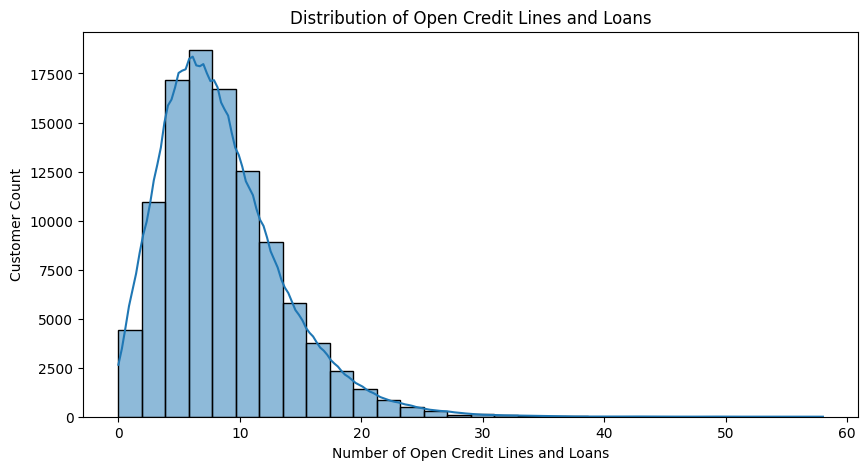

In [57]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='NumberOfOpenCreditLinesAndLoans',
    bins=30,
    kde=True
)

plt.title('Distribution of Open Credit Lines and Loans')
plt.xlabel('Number of Open Credit Lines and Loans')
plt.ylabel('Customer Count')
plt.show()

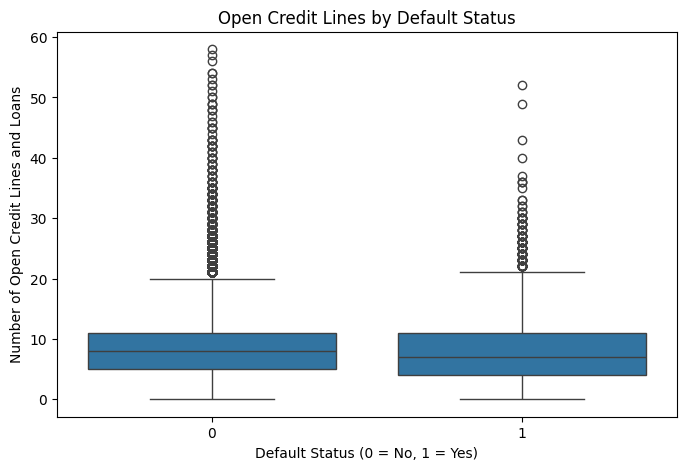

In [58]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='SeriousDlqin2yrs',
    y='NumberOfOpenCreditLinesAndLoans'
)

plt.title('Open Credit Lines by Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Open Credit Lines and Loans')
plt.show()

In [59]:
display(
    df.groupby('SeriousDlqin2yrs')[
        'NumberOfOpenCreditLinesAndLoans'
    ].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
)

,mean,median,std,min,max
SeriousDlqin2yrs,,,,,
0,8.49,8.0,5.09,0,58
1,7.94,7.0,5.64,0,52


In [60]:
feature = 'NumberRealEstateLoansOrLines'

print("FEATURE:", feature)

print("\nBasic Statistics:")
display(df[feature].describe())

print("\nUnique Values:", df[feature].nunique())

print("\nValue Counts:")
display(df[feature].value_counts().sort_index())

FEATURE: NumberRealEstateLoansOrLines

Basic Statistics:


,NumberRealEstateLoansOrLines
count,104805.000000
mean,1.019551
std,1.136847
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,54.000000



Unique Values: 26

Value Counts:


,count
NumberRealEstateLoansOrLines,
0,39244
1,36540
2,22019
3,4471
4,1504
5,466
6,222
7,123
8,69


In [61]:
result = df.groupby(feature)['SeriousDlqin2yrs'].agg(
    Customers='count',
    Defaults='sum',
    Default_Rate='mean'
)

result['Default_Rate'] *= 100

display(result.round(2))

,Customers,Defaults,Default_Rate
NumberRealEstateLoansOrLines,,,
0,39244,3235,8.24
1,36540,1878,5.14
2,22019,1233,5.60
3,4471,308,6.89
4,1504,133,8.84
5,466,58,12.45
6,222,37,16.67
7,123,22,17.89
8,69,18,26.09


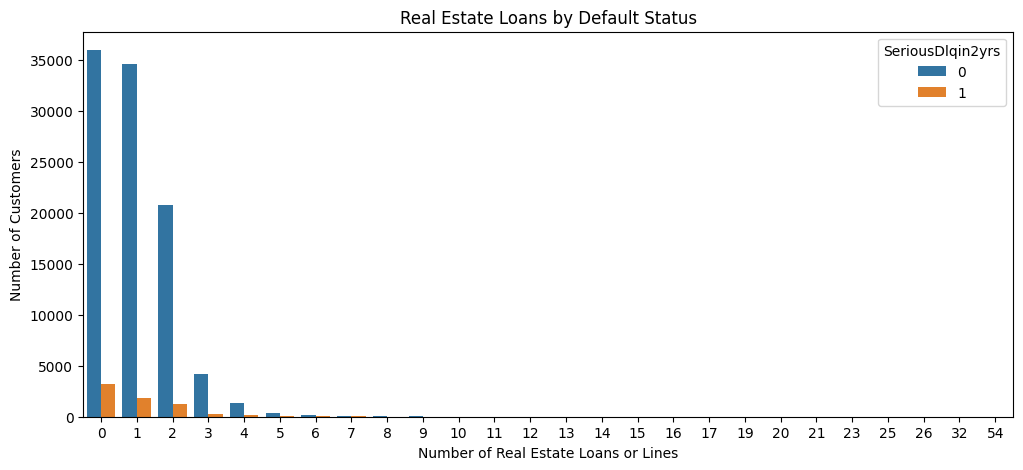

In [62]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x=feature,
    hue='SeriousDlqin2yrs'
)

plt.title('Real Estate Loans by Default Status')
plt.xlabel('Number of Real Estate Loans or Lines')
plt.ylabel('Number of Customers')
plt.show()

In [63]:
display(
    df.groupby('SeriousDlqin2yrs')[feature]
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

,mean,median,std,min,max
SeriousDlqin2yrs,,,,,
0,1.02,1.0,1.12,0,54
1,1.00,1.0,1.41,0,20


In [64]:
feature = 'NumberOfDependents'

print("FEATURE:", feature)

print("\nBasic Statistics:")
display(df[feature].describe())

print("\nMissing Values:", df[feature].isnull().sum())
print("\nUnique Values:", df[feature].nunique())

print("\nValue Counts:")
display(df[feature].value_counts(dropna=False).sort_index())

FEATURE: NumberOfDependents

Basic Statistics:


,NumberOfDependents
count,102056.000000
mean,0.756065
std,1.112162
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,13.000000



Missing Values: 2749

Unique Values: 12

Value Counts:


,count
NumberOfDependents,
0.0,60709
1.0,18474
2.0,13552
3.0,6617
4.0,2043
5.0,500
6.0,104
7.0,35
8.0,14


In [65]:
result = df.groupby(feature, dropna=False)['SeriousDlqin2yrs'].agg(
    Customers='count',
    Defaults='sum',
    Default_Rate='mean'
)

result['Default_Rate'] *= 100

display(result.round(2))

,Customers,Defaults,Default_Rate
NumberOfDependents,,,
0.0,60709,3558,5.86
1.0,18474,1332,7.21
2.0,13552,1062,7.84
3.0,6617,600,9.07
4.0,2043,220,10.77
5.0,500,45,9.00
6.0,104,15,14.42
7.0,35,2,5.71
8.0,14,0,0.00


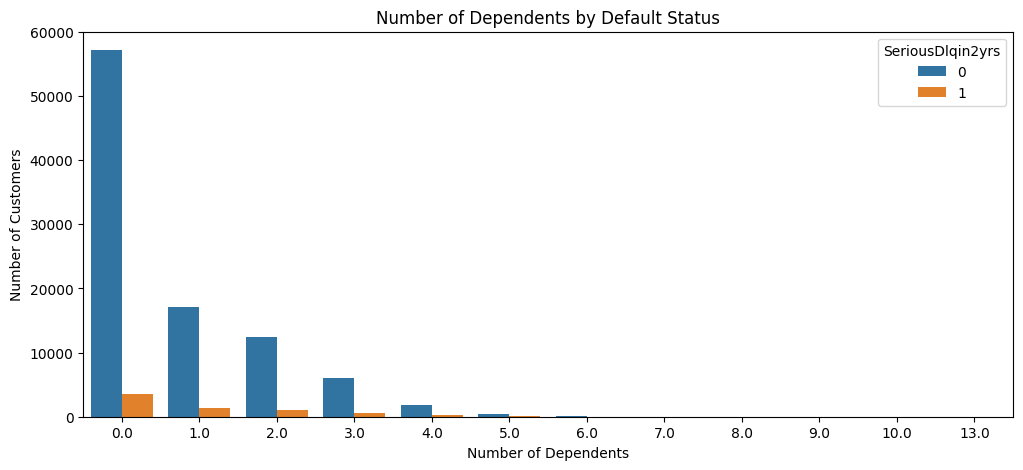

In [66]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x=feature,
    hue='SeriousDlqin2yrs'
)

plt.title('Number of Dependents by Default Status')
plt.xlabel('Number of Dependents')
plt.ylabel('Number of Customers')
plt.show()

In [67]:
display(
    df.groupby('SeriousDlqin2yrs')[feature]
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

,mean,median,std,min,max
SeriousDlqin2yrs,,,,,
0,0.74,0.0,1.10,0.0,13.0
1,0.95,0.0,1.22,0.0,7.0


In [68]:
# Create a separate modeling dataset
model_df = df.copy()

# Remove identifier and temporary EDA columns
columns_to_drop = ['Id', 'ID_Range', 'Income_Status']

model_df.drop(
    columns=columns_to_drop,
    errors='ignore',
    inplace=True
)

print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", model_df.shape)

print("\nRemaining columns:")
print(model_df.columns.tolist())

print("\nMissing values:")
display(model_df.isnull().sum())

Original dataset shape: (104805, 14)
Modeling dataset shape: (104805, 11)

Remaining columns:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Missing values:


,0
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
MonthlyIncome,20781
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0
NumberOfTime60-89DaysPastDueNotWorse,0


In [71]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset Shape: (104805, 14)

Columns:
['Id', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'ID_Range', 'Income_Status']


In [72]:
# Original EDA dataframe ko preserve rakhenge
modeling_df = df.drop(
    columns=['Id', 'ID_Range', 'Income_Status'],
    errors='ignore'
).copy()

print("Original Dataset Shape:", df.shape)
print("Modeling Dataset Shape:", modeling_df.shape)

print("\nRemaining Columns:")
print(modeling_df.columns.tolist())


Original Dataset Shape: (104805, 14)
Modeling Dataset Shape: (104805, 11)

Remaining Columns:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']


In [73]:
print("Dataset Shape:", modeling_df.shape)

print("\nTarget Distribution:")
display(
    modeling_df['SeriousDlqin2yrs']
    .value_counts()
    .to_frame('Count')
)

print("\nTarget Percentage:")
display(
    (modeling_df['SeriousDlqin2yrs']
     .value_counts(normalize=True) * 100)
    .round(2)
)

print("\nDuplicate Rows:", modeling_df.duplicated().sum())

print("\nMissing Values:")
display(modeling_df.isnull().sum())

Dataset Shape: (104805, 11)

Target Distribution:


,Count
SeriousDlqin2yrs,
0,97855
1,6950



Target Percentage:


,proportion
SeriousDlqin2yrs,
0,93.37
1,6.63



Duplicate Rows: 353

Missing Values:


,0
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
MonthlyIncome,20781
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0
NumberOfTime60-89DaysPastDueNotWorse,0


In [74]:
print("Exact duplicate rows:")
print(modeling_df.duplicated().sum())

print("\nAll duplicate rows (including first occurrence):")
print(modeling_df.duplicated(keep=False).sum())

print("\nDuplicate records:")
display(
    modeling_df[
        modeling_df.duplicated(keep=False)
    ].sort_values(
        by=modeling_df.columns.tolist()
    ).head(20)
)


Exact duplicate rows:
353

All duplicate rows (including first occurrence):
582

Duplicate records:


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
17905,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
58432,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
97329,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
70275,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
89181,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0
30759,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
38205,0,0.0,22,0,0.0,0.0,1,0,0,0,0.0
37043,0,0.0,22,0,0.0,1.0,2,0,0,0,0.0
48700,0,0.0,22,0,0.0,1.0,2,0,0,0,0.0
18787,0,0.0,22,0,0.0,820.0,2,0,0,0,0.0


In [75]:
feature_cols = [
    col for col in modeling_df.columns
    if col != 'SeriousDlqin2yrs'
]

duplicate_groups = (
    modeling_df.groupby(feature_cols, dropna=False)
    ['SeriousDlqin2yrs']
    .agg(['count', 'nunique'])
)

print("Repeated feature combinations:")
print((duplicate_groups['count'] > 1).sum())

print("\nRepeated feature combinations with conflicting targets:")
display(
    duplicate_groups[
        (duplicate_groups['count'] > 1) &
        (duplicate_groups['nunique'] > 1)
    ]
)

Repeated feature combinations:
236

Repeated feature combinations with conflicting targets:


count  \
RevolvingUtilizationOfUnsecuredLines age NumberOfTime30-59DaysPastDueNotWorse DebtRatio MonthlyIncome NumberOfOpenCreditLinesAndLoans NumberOfTimes90DaysLate NumberRealEstateLoansOrLines NumberOfTime60-89DaysPastDueNotWorse NumberOfDependents          
1.0                                  21  98                                   0.0       NaN           0                               98                      0                            98                                   0.0                     4   
                                     22  98                                   0.0       0.0           0                               98                      0                            98                                   0.0                     2   
                                                                                        NaN           0                               98                      0                            98                                   NaN                     5   
                                     23  0                                    0.0       0.0           1                               0                       0                            0                                    0.0                     4   
                                     24  0                                    0.0       NaN           0                               1                       0                            0                                    0.0                     2   
                                         98                                   0.0       NaN           0                               98                      0                            98                                   0.0                     3   
                                                                                                                                                                                                                                NaN                     4   
                                     27  0                                    0.0       NaN           0                               0                       0                            0                                    0.0                     3   
                                         98                                   0.0       NaN           0                               98                      0                            98                                   0.0                     4   
                                     29  98                                   0.0       NaN           0                               98                      0                            98                                   0.0                     2   
                                     31  0                                    0.0       NaN           0                               0                       0                            0                                    0.0                     4   
                                         98                                   0.0       NaN           0                               98                      0                            98                                   0.0                     2   
                                     32  0                                    0.0       NaN           0                               0                       0                            0                                    0.0                     4   
                                                                                                                                      1                       0                            0                                    0.0                     2   
                                     36  0                                    0.0       NaN           0                               0                       0                            0        

In [76]:
feature_cols = [
    col for col in modeling_df.columns
    if col != 'SeriousDlqin2yrs'
]

groups = (
    modeling_df.groupby(feature_cols, dropna=False)
    ['SeriousDlqin2yrs']
    .agg(
        Total_Records='count',
        Unique_Targets='nunique',
        Total_Defaults='sum'
    )
)

conflicts = groups[
    (groups['Total_Records'] > 1) &
    (groups['Unique_Targets'] > 1)
]

print("Conflicting feature groups:", len(conflicts))
print("Records involved:", conflicts['Total_Records'].sum())

print("\nConflicting groups summary:")
display(conflicts)

Conflicting feature groups: 25
Records involved: 77

Conflicting groups summary:


Total_Records  \
RevolvingUtilizationOfUnsecuredLines age NumberOfTime30-59DaysPastDueNotWorse DebtRatio MonthlyIncome NumberOfOpenCreditLinesAndLoans NumberOfTimes90DaysLate NumberRealEstateLoansOrLines NumberOfTime60-89DaysPastDueNotWorse NumberOfDependents                  
1.0                                  21  98                                   0.0       NaN           0                               98                      0                            98                                   0.0                             4   
                                     22  98                                   0.0       0.0           0                               98                      0                            98                                   0.0                             2   
                                                                                        NaN           0                               98                      0                            98                                   NaN                             5   
                                     23  0                                    0.0       0.0           1                               0                       0                            0                                    0.0                             4   
                                     24  0                                    0.0       NaN           0                               1                       0                            0                                    0.0                             2   
                                         98                                   0.0       NaN           0                               98                      0                            98                                   0.0                             3   
                                                                                                                                                                                                                                NaN                             4   
                                     27  0                                    0.0       NaN           0                               0                       0                            0                                    0.0                             3   
                                         98                                   0.0       NaN           0                               98                      0                            98                                   0.0                             4   
                                     29  98                                   0.0       NaN           0                               98                      0                            98                                   0.0                             2   
                                     31  0                                    0.0       NaN           0                               0                       0                            0                                    0.0                             4   
                                         98                                   0.0       NaN           0                               98                      0                            98                                   0.0                             2   
                                     32  0                                    0.0       NaN           0                               0                       0                            0                                    0.0                             4   
                                                                                                                                      1                       0                            0                                    0.0                             2   
                                     36  0                          

In [77]:
grouped = modeling_df.groupby(
    feature_cols,
    dropna=False,
    sort=False
)

conflict_indices = []

for _, group in grouped:
    if group['SeriousDlqin2yrs'].nunique() > 1:
        conflict_indices.extend(group.index.tolist())

conflict_records = modeling_df.loc[conflict_indices]

display(
    conflict_records.sort_values(feature_cols).head(30)
)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
5346,1,1.0,21,98,0.0,NaN,0,98,0,98,0.0
13121,0,1.0,21,98,0.0,NaN,0,98,0,98,0.0
55170,0,1.0,21,98,0.0,NaN,0,98,0,98,0.0
98009,1,1.0,21,98,0.0,NaN,0,98,0,98,0.0
34513,1,1.0,22,98,0.0,0.0,0,98,0,98,0.0
78243,0,1.0,22,98,0.0,0.0,0,98,0,98,0.0
20995,0,1.0,22,98,0.0,NaN,0,98,0,98,NaN
37242,0,1.0,22,98,0.0,NaN,0,98,0,98,NaN
46108,0,1.0,22,98,0.0,NaN,0,98,0,98,NaN
57616,1,1.0,22,98,0.0,NaN,0,98,0,98,NaN


In [78]:
late_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

special_mask = modeling_df[late_cols].eq(98).all(axis=1)

print("Records with 98 in all three late-payment columns:",
      special_mask.sum())

print("\nTarget distribution in these records:")
display(
    modeling_df.loc[special_mask, 'SeriousDlqin2yrs']
    .value_counts()
)

print("\nDefault rate in these records:")
print(
    modeling_df.loc[special_mask, 'SeriousDlqin2yrs'].mean() * 100
)

Records with 98 in all three late-payment columns: 181

Target distribution in these records:


,count
SeriousDlqin2yrs,
1,95
0,86



Default rate in these records:
52.48618784530387


In [79]:
special_mask_96 = modeling_df[late_cols].eq(96).all(axis=1)

print("Records with 96 in all three columns:",
      special_mask_96.sum())

print("\nTarget distribution:")
display(
    modeling_df.loc[special_mask_96, 'SeriousDlqin2yrs']
    .value_counts()
)

print("\nDefault rate:")
print(
    modeling_df.loc[special_mask_96, 'SeriousDlqin2yrs'].mean() * 100
)

Records with 96 in all three columns: 2

Target distribution:


,count
SeriousDlqin2yrs,
1,1
0,1



Default rate:
50.0


In [80]:
duplicate_mask = modeling_df.duplicated(keep=False)

duplicate_indices = modeling_df.index[duplicate_mask]

duplicate_check = df.loc[
    duplicate_indices,
    ['Id', 'SeriousDlqin2yrs']
]

print("Rows in duplicate groups:",
      len(duplicate_check))

print("Unique original IDs:",
      duplicate_check['Id'].nunique())

print("Duplicate original IDs:",
      duplicate_check['Id'].duplicated().sum())

display(duplicate_check.head(20))

Rows in duplicate groups: 582
Unique original IDs: 582
Duplicate original IDs: 0


,Id,SeriousDlqin2yrs
357,530,0
1176,1719,0
1292,1897,0
1295,1900,0
1353,1988,0
1556,2286,0
1756,2555,0
1760,2563,0
1915,2778,0
2324,3367,0


In [81]:
# Check target and feature columns

target = 'SeriousDlqin2yrs'

X = modeling_df.drop(columns=[target])
y = modeling_df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:")
display(X.isnull().sum().sort_values(ascending=False))

print("\nTarget distribution:")
display(y.value_counts(normalize=True) * 100)

Features shape: (104805, 10)
Target shape: (104805,)

Missing values:


,0
MonthlyIncome,20781
NumberOfDependents,2749
age,0
RevolvingUtilizationOfUnsecuredLines,0
DebtRatio,0
NumberOfTime30-59DaysPastDueNotWorse,0
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0
NumberOfTime60-89DaysPastDueNotWorse,0



Target distribution:


,proportion
SeriousDlqin2yrs,
0,93.368637
1,6.631363


In [82]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# 1. Separate features and target
X = modeling_df.drop(columns=['SeriousDlqin2yrs']).copy()
y = modeling_df['SeriousDlqin2yrs'].copy()

# 2. Treat age = 0 as missing
X.loc[X['age'] == 0, 'age'] = float('nan')

# 3. Create groups using identical feature combinations
groups = X.groupby(
    list(X.columns),
    dropna=False,
    sort=False
).ngroup()

# 4. Stratified group split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

# 5. Create train and test datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# 6. Verify split
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

print("\nMissing age values in training:", X_train['age'].isna().sum())
print("Missing age values in testing:", X_test['age'].isna().sum())

print("\nGroups shared between train and test:",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Training shape: (83844, 10)
Testing shape: (20961, 10)

Training target distribution:
SeriousDlqin2yrs
0    93.417537
1     6.582463
Name: proportion, dtype: float64

Testing target distribution:
SeriousDlqin2yrs
0    93.173036
1     6.826964
Name: proportion, dtype: float64

Missing age values in training: 1
Missing age values in testing: 0

Groups shared between train and test: 0


In [83]:
from sklearn.impute import SimpleImputer

# Create median imputer
imputer = SimpleImputer(
    strategy='median',
    add_indicator=True
)

# Fit only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Transform test data
X_test_imputed = imputer.transform(X_test)

print("Original training shape:", X_train.shape)
print("Transformed training shape:", X_train_imputed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Transformed testing shape:", X_test_imputed.shape)

print("\nMissing values after imputation:",
      pd.DataFrame(X_train_imputed).isnull().sum().sum())

Original training shape: (83844, 10)
Transformed training shape: (83844, 13)

Original testing shape: (20961, 10)
Transformed testing shape: (20961, 13)

Missing values after imputation: 0


In [84]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data only
X_train_scaled = scaler.fit_transform(X_train_imputed)

# Apply same scaling to testing data
X_test_scaled = scaler.transform(X_test_imputed)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_train_scaled[:5])

Training shape: (83844, 13)
Testing shape: (20961, 13)

First 5 scaled rows:
[[-0.02318214 -0.83602215 -0.09993698 -0.15748307 -0.25461551 -0.86819705
  -0.06375218 -0.89256266 -0.05762069  0.23739349 -0.00345356 -0.49810215
  -0.16522279]
 [-0.02473901 -0.97151823  0.13807905 -0.15749917 -0.22522344 -1.25821169
   0.17552611 -0.89256266 -0.05762069 -0.66717022 -0.00345356 -0.49810215
  -0.16522279]
 [-0.02694889 -1.51350255 -0.09993698 -0.15752067 -0.20806698 -0.67318973
  -0.06375218 -0.89256266 -0.05762069 -0.66717022 -0.00345356 -0.49810215
  -0.16522279]
 [-0.02705632  1.46741119 -0.09993698 -0.15737191 -0.19476739 -1.06320437
  -0.06375218 -0.01740012 -0.05762069  0.23739349 -0.00345356 -0.49810215
  -0.16522279]
 [-0.02657462  0.31569452 -0.09993698  2.34396776 -0.06842138 -0.08816776
  -0.06375218  1.73292496 -0.05762069 -0.66717022 -0.00345356  2.00762033
  -0.16522279]]


In [85]:
print("Imputer feature names:")
print(imputer.get_feature_names_out())

Imputer feature names:
['RevolvingUtilizationOfUnsecuredLines' 'age'
 'NumberOfTime30-59DaysPastDueNotWorse' 'DebtRatio' 'MonthlyIncome'
 'NumberOfOpenCreditLinesAndLoans' 'NumberOfTimes90DaysLate'
 'NumberRealEstateLoansOrLines' 'NumberOfTime60-89DaysPastDueNotWorse'
 'NumberOfDependents' 'missingindicator_age'
 'missingindicator_MonthlyIncome' 'missingindicator_NumberOfDependents']


In [87]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Logistic Regression preprocessing
logistic_preprocessor = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

# Random Forest preprocessing
rf_preprocessor = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    ))
])

print("Logistic preprocessing ready!")
print("Random Forest preprocessing ready!")

Logistic preprocessing ready!
Random Forest preprocessing ready!


In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_model = Pipeline([
    ('preprocessing', logistic_preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))
])

random_forest_model = Pipeline([
    ('preprocessing', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Both models created successfully!")

Both models created successfully!


In [89]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
import pandas as pd

groups_train = groups.iloc[train_idx]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

models = {
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest_model
}

results = {}

for name, model in models.items():

    print(f"\nEvaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    results[name] = {
        metric: scores[f'test_{metric}'].mean()
        for metric in scoring
    }

    print("Completed!")


Evaluating Logistic Regression...
Completed!

Evaluating Random Forest...
Completed!


In [90]:
results_df = pd.DataFrame(results).T

display(
    results_df.round(4).sort_values(
        by='pr_auc',
        ascending=False
    )
)

,precision,recall,f1,roc_auc,pr_auc
Random Forest,0.4778,0.2967,0.3659,0.8503,0.3628
Logistic Regression,0.1624,0.6547,0.2601,0.7838,0.2943


In [91]:
from sklearn.model_selection import cross_val_predict

# Out-of-fold probabilities
lr_oof_prob = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

print("OOF predictions shape:", lr_oof_prob.shape)
print("\nFirst 10 probabilities:")
print(lr_oof_prob[:10])

OOF predictions shape: (83844,)

First 10 probabilities:
[0.46098623 0.70535824 0.52063521 0.2329176  0.32371017 0.45516398
 0.48974603 0.42354887 0.42367667 0.93239534]


In [92]:
rf_oof_prob = cross_val_predict(
    random_forest_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

print("OOF predictions shape:", rf_oof_prob.shape)
print("\nFirst 10 probabilities:")
print(rf_oof_prob[:10])

OOF predictions shape: (83844,)

First 10 probabilities:
[0.17392529 0.34795315 0.02225444 0.01330083 0.0012415  0.07965977
 0.02582219 0.00949526 0.00992247 0.80100255]


In [93]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

def threshold_analysis(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # F1 for every available threshold
    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    # Best F1 threshold
    best_f1_idx = np.argmax(f1_values)
    best_f1_threshold = thresholds[best_f1_idx]

    # Highest threshold that still achieves recall >= 60%
    eligible = np.where(recall[:-1] >= 0.60)[0]

    recall_threshold = (
        thresholds[eligible[-1]]
        if len(eligible) > 0
        else None
    )

    selected_thresholds = {
        'Default 0.50': 0.50,
        'Best F1': best_f1_threshold
    }

    if recall_threshold is not None:
        selected_thresholds['Recall >= 60%'] = recall_threshold

    rows = []

    for name, threshold in selected_thresholds.items():

        predictions = (probabilities >= threshold).astype(int)

        rows.append({
            'Strategy': name,
            'Threshold': threshold,
            'Precision': precision_score(
                y_true, predictions, zero_division=0
            ),
            'Recall': recall_score(
                y_true, predictions, zero_division=0
            ),
            'F1': f1_score(
                y_true, predictions, zero_division=0
            )
        })

    return pd.DataFrame(rows)


# Logistic Regression
print("LOGISTIC REGRESSION")
lr_threshold_results = threshold_analysis(
    y_train, lr_oof_prob
)
display(lr_threshold_results.round(4))


# Random Forest
print("RANDOM FOREST")
rf_threshold_results = threshold_analysis(
    y_train, rf_oof_prob
)
display(rf_threshold_results.round(4))

LOGISTIC REGRESSION


,Strategy,Threshold,Precision,Recall,F1
0,Default 0.50,0.5000,0.1619,0.6546,0.2596
1,Best F1,0.6337,0.3393,0.4051,0.3693
2,Recall >= 60%,0.5231,0.1826,0.6001,0.2800


RANDOM FOREST


,Strategy,Threshold,Precision,Recall,F1
0,Default 0.50,0.5000,0.4777,0.2964,0.3658
1,Best F1,0.3395,0.3796,0.4671,0.4188
2,Recall >= 60%,0.2262,0.2934,0.6001,0.3941


In [94]:
rf_threshold = 0.2262

rf_predictions_60 = (
    rf_oof_prob >= rf_threshold
).astype(int)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Threshold:", rf_threshold)

print("Precision:", precision_score(
    y_train, rf_predictions_60
))

print("Recall:", recall_score(
    y_train, rf_predictions_60
))

print("F1:", f1_score(
    y_train, rf_predictions_60
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, rf_predictions_60))

Threshold: 0.2262
Precision: 0.29339355295784625
Recall: 0.6002899075919551
F1: 0.3941466896674796

Confusion Matrix:
[[70346  7979]
 [ 2206  3313]]


In [95]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import pandas as pd

# Train Random Forest on complete training data
random_forest_model.fit(X_train, y_train)

# Predict probabilities on untouched test data
rf_test_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Thresholds selected using training OOF predictions
thresholds_to_test = {
    "Default": 0.50,
    "Best F1": 0.3395,
    "Recall >= 60%": 0.2262
}

results = []

for strategy, threshold in thresholds_to_test.items():

    test_pred = (rf_test_prob >= threshold).astype(int)

    results.append({
        "Strategy": strategy,
        "Threshold": threshold,
        "Precision": precision_score(y_test, test_pred),
        "Recall": recall_score(y_test, test_pred),
        "F1": f1_score(y_test, test_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_test_prob),
        "PR-AUC": average_precision_score(y_test, rf_test_prob)
    })

results_df = pd.DataFrame(results)

print("RANDOM FOREST - FINAL TEST RESULTS")
display(results_df.round(4))

RANDOM FOREST - FINAL TEST RESULTS


,Strategy,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Default,0.5000,0.4936,0.2963,0.3703,0.8518,0.3732
1,Best F1,0.3395,0.4000,0.4892,0.4401,0.8518,0.3732
2,Recall >= 60%,0.2262,0.3081,0.6191,0.4114,0.8518,0.3732


In [96]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Fit Random Forest on complete training data
random_forest_model.fit(X_train, y_train)

# Predict probabilities on untouched test data
rf_test_prob = random_forest_model.predict_proba(X_test)[:, 1]

# Best F1 threshold selected using training OOF predictions
best_threshold = 0.3395

# Predictions at selected threshold
rf_test_pred = (rf_test_prob >= best_threshold).astype(int)

print("RANDOM FOREST - FINAL TEST RESULTS")
print("=" * 45)

print("Threshold:", best_threshold)
print("Precision:", precision_score(y_test, rf_test_pred))
print("Recall:", recall_score(y_test, rf_test_pred))
print("F1 Score:", f1_score(y_test, rf_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_test_prob))
print("PR-AUC:", average_precision_score(y_test, rf_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_test_pred))

RANDOM FOREST - FINAL TEST RESULTS
Threshold: 0.3395
Precision: 0.4
Recall: 0.4891684136967156
F1 Score: 0.44011317195850364
ROC-AUC: 0.8518206861954747
PR-AUC: 0.3731706818815172

Confusion Matrix:
[[18480  1050]
 [  731   700]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.95     19530
           1       0.40      0.49      0.44      1431

    accuracy                           0.92     20961
   macro avg       0.68      0.72      0.70     20961
weighted avg       0.92      0.92      0.92     20961



In [97]:
print("TRAIN / TEST SANITY CHECK")
print("=" * 40)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("Overlapping indices:",
      len(set(X_train.index) & set(X_test.index)))

print("Test features match original split:",
      X_test.equals(X.iloc[test_idx]))

print("Test target matches original split:",
      y_test.equals(y.iloc[test_idx]))

print("Test probability count:", len(rf_test_prob))
print("Test probability range:",
      rf_test_prob.min(), rf_test_prob.max())

TRAIN / TEST SANITY CHECK
X_train shape: (83844, 10)
X_test shape: (20961, 10)
Overlapping indices: 0
Test features match original split: True
Test target matches original split: True
Test probability count: 20961
Test probability range: 0.0 0.9535420329751937


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,RevolvingUtilizationOfUnsecuredLines,0.267751
1,DebtRatio,0.129676
2,age,0.115283
3,MonthlyIncome,0.105848
4,NumberOfTime30-59DaysPastDueNotWorse,0.093686
5,NumberOfTimes90DaysLate,0.087925
6,NumberOfOpenCreditLinesAndLoans,0.081078
7,NumberOfTime60-89DaysPastDueNotWorse,0.048688
8,NumberRealEstateLoansOrLines,0.032291
9,NumberOfDependents,0.030955


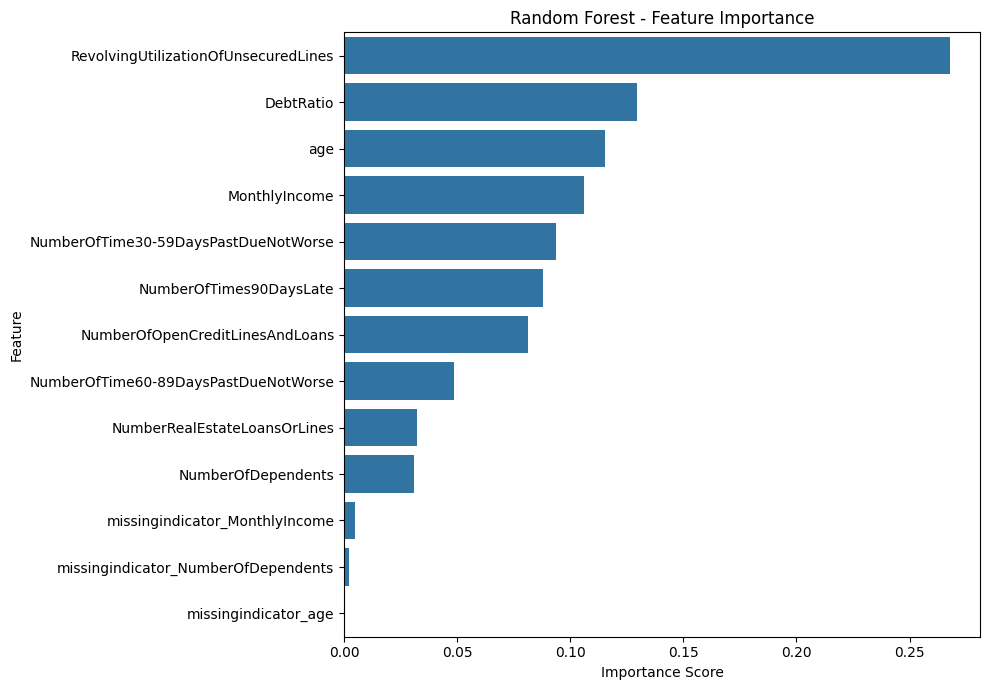

In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract trained Random Forest
rf_classifier = random_forest_model.named_steps['classifier']

# Get transformed feature names after imputation
feature_names = (
    random_forest_model
    .named_steps['preprocessing']
    .named_steps['imputer']
    .get_feature_names_out()
)

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

# Sort descending
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(importance_df)

# Visualize
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

,Feature,Importance_Mean,Importance_STD
0,RevolvingUtilizationOfUnsecuredLines,0.064444,0.002798
1,NumberOfTimes90DaysLate,0.034022,0.001604
2,NumberOfTime30-59DaysPastDueNotWorse,0.031257,0.001207
3,NumberOfTime60-89DaysPastDueNotWorse,0.019763,0.000944
4,age,0.014580,0.002658
5,DebtRatio,0.008308,0.001851
6,MonthlyIncome,0.006613,0.000736
7,NumberOfDependents,0.003867,0.000447
8,NumberOfOpenCreditLinesAndLoans,0.003568,0.001194
9,NumberRealEstateLoansOrLines,0.001347,0.000797


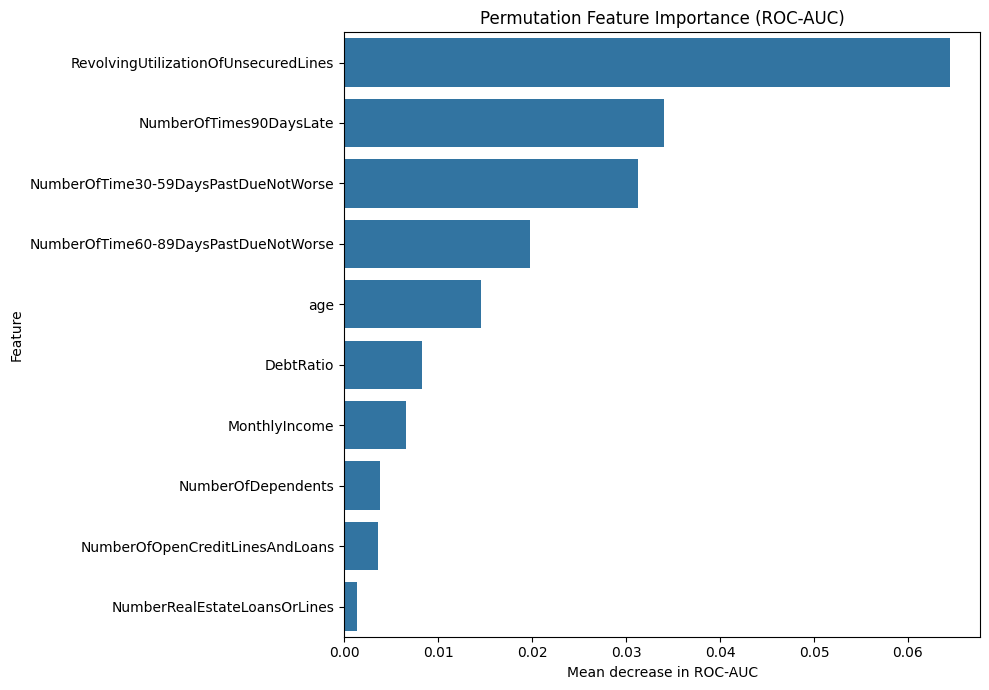

In [99]:
from sklearn.inspection import permutation_importance

# Permutation importance on final test data
perm_result = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create dataframe
permutation_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm_result.importances_mean,
    'Importance_STD': perm_result.importances_std
})

# Sort
permutation_df = permutation_df.sort_values(
    by='Importance_Mean',
    ascending=False
).reset_index(drop=True)

display(permutation_df)

# Visualization
plt.figure(figsize=(10, 7))

sns.barplot(
    data=permutation_df,
    x='Importance_Mean',
    y='Feature'
)

plt.title('Permutation Feature Importance (ROC-AUC)')
plt.xlabel('Mean decrease in ROC-AUC')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [100]:
# Create an error analysis dataframe
error_df = X_test.copy()

error_df['Actual'] = y_test
error_df['Predicted'] = rf_test_pred
error_df['Default_Probability'] = rf_test_prob

# Identify error categories
error_df['Error_Type'] = 'Correct'

error_df.loc[
    (error_df['Actual'] == 1) &
    (error_df['Predicted'] == 0),
    'Error_Type'
] = 'False Negative'

error_df.loc[
    (error_df['Actual'] == 0) &
    (error_df['Predicted'] == 1),
    'Error_Type'
] = 'False Positive'

print("ERROR DISTRIBUTION")
display(error_df['Error_Type'].value_counts())

print("\nERROR PERCENTAGES")
display(
    error_df['Error_Type']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

ERROR DISTRIBUTION


,count
Error_Type,
Correct,19180
False Positive,1050
False Negative,731



ERROR PERCENTAGES


,proportion
Error_Type,
Correct,91.50
False Positive,5.01
False Negative,3.49


In [101]:
# Actual defaulters missed by the model
false_negatives = error_df[
    error_df['Error_Type'] == 'False Negative'
]

# Actual defaulters correctly identified
true_positives = error_df[
    error_df['Error_Type'] == 'Correct'
].query("Actual == 1")

compare_features = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'NumberOfTimes90DaysLate'
]

comparison = pd.DataFrame({
    'False_Negatives': false_negatives[compare_features].median(),
    'True_Positives': true_positives[compare_features].median()
})

display(comparison)

,False_Negatives,True_Positives
RevolvingUtilizationOfUnsecuredLines,0.506189,0.998717
age,46.000000,44.000000
NumberOfTime30-59DaysPastDueNotWorse,0.000000,1.000000
DebtRatio,0.409412,0.452684
MonthlyIncome,5000.000000,4125.000000
NumberOfTimes90DaysLate,0.000000,1.000000


In [102]:
# False Negative probability analysis
fn_prob = false_negatives['Default_Probability']

print("FALSE NEGATIVE PROBABILITY ANALYSIS")
print("=" * 45)

print("Count:", len(fn_prob))
print("Mean:", fn_prob.mean())
print("Median:", fn_prob.median())
print("Minimum:", fn_prob.min())
print("Maximum:", fn_prob.max())

print("\nProbability distribution:")
display(fn_prob.describe())

# Probability bands
probability_bands = pd.cut(
    fn_prob,
    bins=[0, 0.10, 0.20, 0.30, 0.3395, 1.0],
    labels=[
        '0–0.10',
        '0.10–0.20',
        '0.20–0.30',
        '0.30–0.3395',
        '0.3395–1.00'
    ],
    include_lowest=True
)

display(probability_bands.value_counts().sort_index())

FALSE NEGATIVE PROBABILITY ANALYSIS
Count: 731
Mean: 0.1473742574477337
Median: 0.13591488898228368
Minimum: 0.0
Maximum: 0.3392452828989785

Probability distribution:


,Default_Probability
count,731.000000
mean,0.147374
std,0.097505
min,0.000000
25%,0.061388
50%,0.135915
75%,0.227360
max,0.339245


,count
Default_Probability,
0–0.10,279
0.10–0.20,222
0.20–0.30,172
0.30–0.3395,58
0.3395–1.00,0


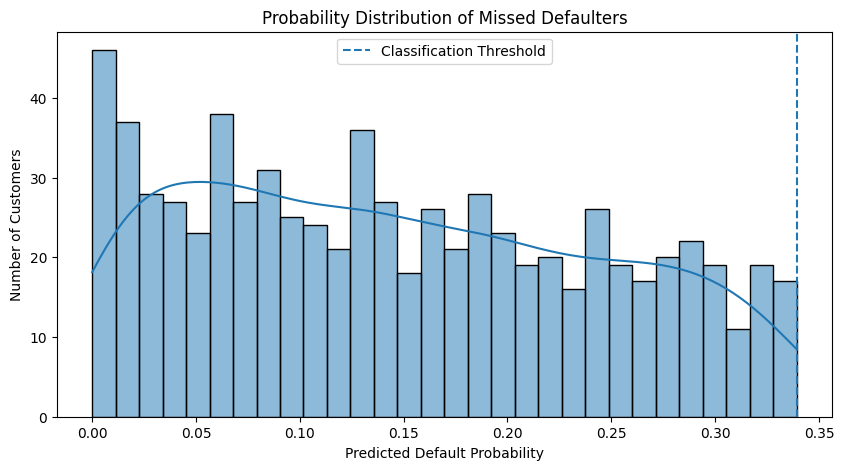

In [103]:
plt.figure(figsize=(10, 5))

sns.histplot(
    false_negatives['Default_Probability'],
    bins=30,
    kde=True
)

plt.axvline(
    0.3395,
    linestyle='--',
    label='Classification Threshold'
)

plt.title('Probability Distribution of Missed Defaulters')
plt.xlabel('Predicted Default Probability')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

In [104]:
# Extract probability distributions by prediction category

tp_prob = error_df.loc[
    error_df['Error_Type'] == 'Correct'
].query("Actual == 1")['Default_Probability']

fp_prob = error_df.loc[
    error_df['Error_Type'] == 'False Positive',
    'Default_Probability'
]

fn_prob = error_df.loc[
    error_df['Error_Type'] == 'False Negative',
    'Default_Probability'
]

probability_comparison = pd.DataFrame({
    'True Positives': tp_prob.describe(),
    'False Negatives': fn_prob.describe(),
    'False Positives': fp_prob.describe()
})

display(probability_comparison)

,True Positives,False Negatives,False Positives
count,700.000000,731.000000,1050.000000
mean,0.570210,0.147374,0.504840
std,0.154381,0.097505,0.134161
min,0.340847,0.000000,0.339541
25%,0.433804,0.061388,0.395909
50%,0.549290,0.135915,0.467457
75%,0.691818,0.227360,0.585705
max,0.953542,0.339245,0.936292


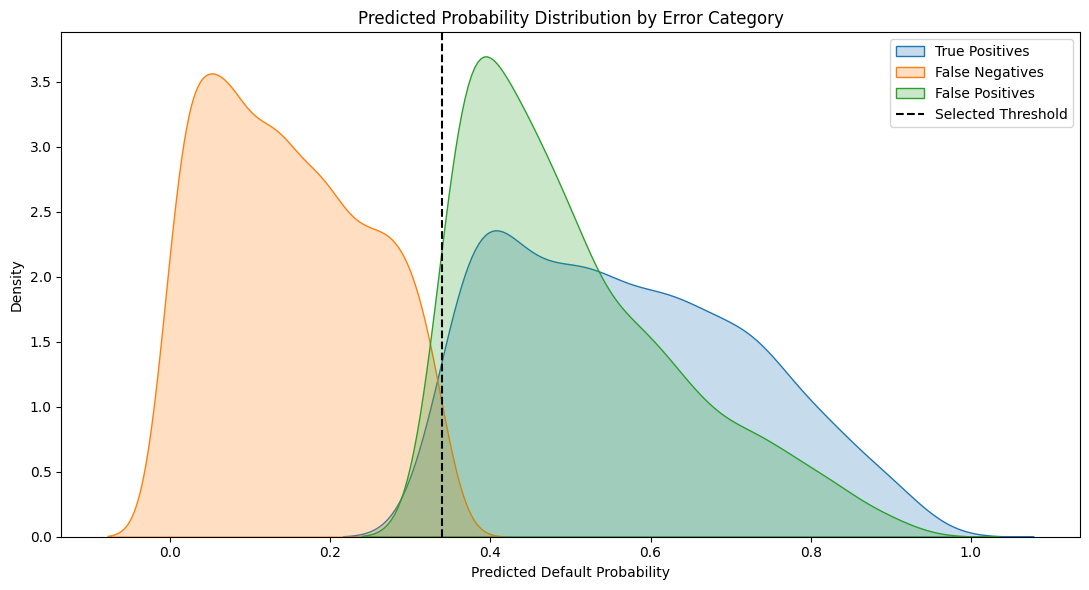

In [105]:
plt.figure(figsize=(11, 6))

sns.kdeplot(
    tp_prob,
    label='True Positives',
    fill=True
)

sns.kdeplot(
    fn_prob,
    label='False Negatives',
    fill=True
)

sns.kdeplot(
    fp_prob,
    label='False Positives',
    fill=True
)

plt.axvline(
    0.3395,
    color='black',
    linestyle='--',
    label='Selected Threshold'
)

plt.title('Predicted Probability Distribution by Error Category')
plt.xlabel('Predicted Default Probability')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

In [106]:
late_payment_features = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

# Check special values in training data
for col in late_payment_features:
    print(f"\n{col}")
    print(X_train[col].value_counts().sort_index().tail(10))


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
5     184
6      68
7      36
8      13
9       5
10      2
12      2
13      1
96      2
98    149
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
1     3133
2      604
3      175
4       67
5       17
6        9
7        6
9        1
96       2
98     149
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
9      12
10      5
11      3
12      2
13      2
14      2
15      1
17      1
96      2
98    149
Name: count, dtype: int64


In [109]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

late_payment_features = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

other_features = [
    col for col in X_train.columns
    if col not in late_payment_features
]


class SpecialCodeHandler(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()

        # Identify special codes
        special_mask = np.isin(X, [96, 98])

        # Replace special codes with NaN
        X[special_mask] = np.nan

        # Append explicit special-code indicators
        return np.column_stack([
            X,
            special_mask.astype(int)
        ])


late_pipeline = Pipeline([
    ('special_handler', SpecialCodeHandler()),
    ('imputer', SimpleImputer(strategy='median'))
])

other_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True))
])

special_preprocessor = ColumnTransformer([
    ('late', late_pipeline, late_payment_features),
    ('other', other_pipeline, other_features)
])

special_rf_model = Pipeline([
    ('preprocessing', special_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Special-code preprocessing pipeline created.")

Special-code preprocessing pipeline created.


In [110]:
X_train_special = special_preprocessor.fit_transform(X_train)

print("Original shape:", X_train.shape)
print("Transformed shape:", X_train_special.shape)

print("Missing values after preprocessing:",
      np.isnan(X_train_special).sum())

print("\nSpecial codes in original training data:")

for col in late_payment_features:
    print(col, X_train[col].isin([96, 98]).sum())

Original shape: (83844, 10)
Transformed shape: (83844, 16)
Missing values after preprocessing: 0

Special codes in original training data:
NumberOfTime30-59DaysPastDueNotWorse 151
NumberOfTime60-89DaysPastDueNotWorse 151
NumberOfTimes90DaysLate 151


In [111]:
from sklearn.model_selection import cross_validate, StratifiedGroupKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
import pandas as pd

# Same CV strategy as baseline
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

# Original baseline
baseline_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# Special-code experiment
special_cv = cross_validate(
    special_rf_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# Compare mean scores
comparison_df = pd.DataFrame({
    'Baseline_RF': {
        metric: baseline_cv[f'test_{metric}'].mean()
        for metric in scoring
    },
    'Special_Code_RF': {
        metric: special_cv[f'test_{metric}'].mean()
        for metric in scoring
    }
})

comparison_df['Difference'] = (
    comparison_df['Special_Code_RF']
    - comparison_df['Baseline_RF']
)

display(comparison_df.round(4))

,Baseline_RF,Special_Code_RF,Difference
precision,0.4778,0.4753,-0.0025
recall,0.2967,0.2986,0.0019
f1,0.3659,0.3665,0.0006
roc_auc,0.8503,0.8502,-0.0001
pr_auc,0.3628,0.3623,-0.0005


In [112]:
fold_comparison = pd.DataFrame({
    'Baseline_RF_F1': baseline_cv['test_f1'],
    'Special_Code_RF_F1': special_cv['test_f1'],
    'Baseline_RF_PR_AUC': baseline_cv['test_pr_auc'],
    'Special_Code_RF_PR_AUC': special_cv['test_pr_auc']
})

fold_comparison['F1_Difference'] = (
    fold_comparison['Special_Code_RF_F1']
    - fold_comparison['Baseline_RF_F1']
)

fold_comparison['PR_AUC_Difference'] = (
    fold_comparison['Special_Code_RF_PR_AUC']
    - fold_comparison['Baseline_RF_PR_AUC']
)

display(fold_comparison.round(4))

,Baseline_RF_F1,Special_Code_RF_F1,Baseline_RF_PR_AUC,Special_Code_RF_PR_AUC,F1_Difference,PR_AUC_Difference
0,0.3576,0.3503,0.3723,0.3721,-0.0073,-0.0002
1,0.3563,0.3574,0.3544,0.3552,0.0011,0.0008
2,0.3851,0.3857,0.3802,0.3771,0.0007,-0.0031
3,0.3516,0.3683,0.3572,0.3588,0.0167,0.0016
4,0.3788,0.3707,0.3498,0.3482,-0.0081,-0.0016


In [113]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.model_selection import cross_validate
import numpy as np
import pandas as pd

In [114]:
hist_gb_model = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('classifier', HistGradientBoostingClassifier(
        learning_rate=0.1,
        max_iter=200,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

In [115]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import numpy as np

class BalancedHistGradientBoosting(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        learning_rate=0.1,
        max_iter=200,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ):
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.max_leaf_nodes = max_leaf_nodes
        self.l2_regularization = l2_regularization
        self.random_state = random_state

    def fit(self, X, y):
        sample_weights = compute_sample_weight(
            class_weight='balanced',
            y=y
        )

        self.model_ = Pipeline([
            ('imputer', SimpleImputer(
                strategy='median',
                add_indicator=True
            )),
            ('classifier', HistGradientBoostingClassifier(
                learning_rate=self.learning_rate,
                max_iter=self.max_iter,
                max_leaf_nodes=self.max_leaf_nodes,
                l2_regularization=self.l2_regularization,
                random_state=self.random_state
            ))
        ])

        self.model_.fit(
            X, y,
            classifier__sample_weight=sample_weights
        )

        self.classes_ = self.model_.classes_
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


hist_gb_model = BalancedHistGradientBoosting()

In [116]:
hist_gb_cv = cross_validate(
    hist_gb_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

print("HistGradientBoosting CV Results")

for metric in scoring:
    scores = hist_gb_cv[f'test_{metric}']

    print(
        f"{metric}: {scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

HistGradientBoosting CV Results
precision: 0.2151 +/- 0.0066
recall: 0.7590 +/- 0.0113
f1: 0.3351 +/- 0.0072
roc_auc: 0.8629 +/- 0.0041
pr_auc: 0.3909 +/- 0.0056


In [117]:
from sklearn.model_selection import cross_val_predict

hist_gb_oof_prob = cross_val_predict(
    hist_gb_model,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

print("OOF Probability Shape:", hist_gb_oof_prob.shape)
print("Minimum Probability:", hist_gb_oof_prob.min())
print("Maximum Probability:", hist_gb_oof_prob.max())

OOF Probability Shape: (83844,)
Minimum Probability: 0.018755328101722923
Maximum Probability: 0.9755579022284985


In [118]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

precision, recall, thresholds = precision_recall_curve(
    y_train,
    hist_gb_oof_prob
)

# Best F1 threshold
f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_f1_idx = np.argmax(f1_values)
best_f1_threshold = thresholds[best_f1_idx]

# Recall >= 60% threshold
eligible = np.where(recall[:-1] >= 0.60)[0]

recall_threshold = (
    thresholds[eligible[-1]]
    if len(eligible) > 0
    else None
)

print("Best F1 Threshold:", best_f1_threshold)
print("Best F1:", f1_values[best_f1_idx])
print("Recall >= 60% Threshold:", recall_threshold)

Best F1 Threshold: 0.7689640147941182
Best F1: 0.4411023621555807
Recall >= 60% Threshold: 0.6770030610227619


In [119]:
thresholds_to_test = {
    'Default 0.50': 0.50,
    'Best F1': best_f1_threshold,
    'Recall >= 60%': recall_threshold
}

results = []

for strategy, threshold in thresholds_to_test.items():

    predictions = (
        hist_gb_oof_prob >= threshold
    ).astype(int)

    results.append({
        'Strategy': strategy,
        'Threshold': threshold,
        'Precision': precision_score(y_train, predictions),
        'Recall': recall_score(y_train, predictions),
        'F1': f1_score(y_train, predictions)
    })

hist_threshold_df = pd.DataFrame(results)

display(hist_threshold_df.round(4))

,Strategy,Threshold,Precision,Recall,F1
0,Default 0.50,0.500,0.2150,0.7588,0.3351
1,Best F1,0.769,0.3901,0.5075,0.4411
2,Recall >= 60%,0.677,0.3185,0.6001,0.4161


In [120]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

def evaluate_oof_model(y_true, probabilities, model_name):

    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_values)
    eligible = np.where(recall[:-1] >= 0.60)[0]

    recall_idx = eligible[-1]

    selected_thresholds = {
        'Default 0.50': 0.50,
        'Best F1': thresholds[best_idx],
        'Recall >= 60%': thresholds[recall_idx]
    }

    results = []

    for strategy, threshold in selected_thresholds.items():

        pred = (probabilities >= threshold).astype(int)

        from sklearn.metrics import (
            precision_score,
            recall_score,
            f1_score
        )

        results.append({
            'Model': model_name,
            'Strategy': strategy,
            'Threshold': threshold,
            'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred)
        })

    return results


all_results = []

all_results += evaluate_oof_model(
    y_train, lr_oof_prob, 'Logistic Regression'
)

all_results += evaluate_oof_model(
    y_train, rf_oof_prob, 'Random Forest'
)

all_results += evaluate_oof_model(
    y_train, hist_gb_oof_prob, 'HistGradientBoosting'
)

final_oof_comparison = pd.DataFrame(all_results)

display(final_oof_comparison.round(4))

,Model,Strategy,Threshold,Precision,Recall,F1
0,Logistic Regression,Default 0.50,0.5000,0.1619,0.6546,0.2596
1,Logistic Regression,Best F1,0.6337,0.3393,0.4051,0.3693
2,Logistic Regression,Recall >= 60%,0.5231,0.1826,0.6001,0.2800
3,Random Forest,Default 0.50,0.5000,0.4777,0.2964,0.3658
4,Random Forest,Best F1,0.3395,0.3796,0.4671,0.4188
5,Random Forest,Recall >= 60%,0.2262,0.2934,0.6001,0.3941
6,HistGradientBoosting,Default 0.50,0.5000,0.2150,0.7588,0.3351
7,HistGradientBoosting,Best F1,0.7690,0.3901,0.5075,0.4411
8,HistGradientBoosting,Recall >= 60%,0.6770,0.3185,0.6001,0.4161


In [121]:
final_model = BalancedHistGradientBoosting(
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

final_model.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [122]:
hist_test_prob = final_model.predict_proba(X_test)[:, 1]

print("Test probability shape:", hist_test_prob.shape)
print("Minimum:", hist_test_prob.min())
print("Maximum:", hist_test_prob.max())

Test probability shape: (20961,)
Minimum: 0.0345789262224516
Maximum: 0.9694798389541894


In [123]:
best_hist_threshold = 0.7689640147941182

hist_test_pred = (
    hist_test_prob >= best_hist_threshold
).astype(int)

print("Predictions generated successfully!")

Predictions generated successfully!


In [124]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Evaluation metrics
print("FINAL TEST RESULTS")
print("-" * 40)

print("Accuracy:",
      accuracy_score(y_test, hist_test_pred))

print("Precision:",
      precision_score(y_test, hist_test_pred))

print("Recall:",
      recall_score(y_test, hist_test_pred))

print("F1 Score:",
      f1_score(y_test, hist_test_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, hist_test_prob))

print("PR-AUC:",
      average_precision_score(y_test, hist_test_prob))


# Confusion Matrix
cm = confusion_matrix(y_test, hist_test_pred)

print("\nConfusion Matrix:")
print(cm)


# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        hist_test_pred,
        target_names=['No Default', 'Default']
    )
)

FINAL TEST RESULTS
----------------------------------------
Accuracy: 0.9135060350174133
Precision: 0.39775160599571735
Recall: 0.5192173305380853
F1 Score: 0.45043952712943314
ROC-AUC: 0.8645979791343963
PR-AUC: 0.4053255742953356

Confusion Matrix:
[[18405  1125]
 [  688   743]]

Classification Report:
              precision    recall  f1-score   support

  No Default       0.96      0.94      0.95     19530
     Default       0.40      0.52      0.45      1431

    accuracy                           0.91     20961
   macro avg       0.68      0.73      0.70     20961
weighted avg       0.93      0.91      0.92     20961



In [125]:
from sklearn.metrics import confusion_matrix
import pandas as pd

FN_COST = 10000
FP_COST = 1000

thresholds = [0.50, 0.60, 0.65, 0.70, 0.769, 0.80]

results = []

for threshold in thresholds:

    predictions = (hist_test_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions
    ).ravel()

    total_cost = (fn * FN_COST) + (fp * FP_COST)

    results.append({
        'Threshold': threshold,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp,
        'Total_Cost': total_cost
    })

cost_df = pd.DataFrame(results)

display(cost_df)

,Threshold,TN,FP,FN,TP,Total_Cost
0,0.500,15577,3953,308,1123,7033000
1,0.600,16947,2583,452,979,7103000
2,0.650,17480,2050,513,918,7180000
3,0.700,17918,1612,585,846,7462000
4,0.769,18405,1125,688,743,8005000
5,0.800,18603,927,753,678,8457000


In [126]:
best_cost_row = cost_df.loc[
    cost_df['Total_Cost'].idxmin()
]

print("Minimum Cost Threshold:")
print(best_cost_row)

Minimum Cost Threshold:
Threshold           0.5
TN              15577.0
FP               3953.0
FN                308.0
TP               1123.0
Total_Cost    7033000.0
Name: 0, dtype: float64


In [127]:
thresholds = [0.50, 0.60, 0.65, 0.70, 0.769, 0.80]

results = []

for threshold in thresholds:
    predictions = (hist_gb_oof_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, predictions
    ).ravel()

    results.append({
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Total_Cost": fn * 10000 + fp * 1000
    })

oof_cost_df = pd.DataFrame(results)
display(oof_cost_df)

,Threshold,FP,FN,Total_Cost
0,0.500,15291,1331,28601000
1,0.600,10215,1786,28075000
2,0.650,8107,2049,28597000
3,0.700,6288,2347,29758000
4,0.769,4379,2719,31569000
5,0.800,3764,2904,32804000


In [128]:
thresholds = np.arange(0.30, 0.81, 0.01)

results = []

for threshold in thresholds:
    pred = (hist_gb_oof_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train, pred
    ).ravel()

    total_cost = fn * 10000 + fp * 1000

    results.append({
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Total_Cost": total_cost
    })

oof_cost_df = pd.DataFrame(results)

display(oof_cost_df.sort_values("Total_Cost").head(10))

,Threshold,FP,FN,Total_Cost
28,0.58,11144,1686,28004000
29,0.59,10719,1731,28029000
30,0.60,10215,1786,28075000
26,0.56,12127,1598,28107000
25,0.55,12657,1547,28127000
27,0.57,11665,1650,28165000
24,0.54,13135,1506,28195000
32,0.62,9297,1895,28247000
33,0.63,8888,1937,28258000
31,0.61,9760,1850,28260000


In [129]:
import joblib

joblib.dump(final_model, "loan_default_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [130]:
from google.colab import files

files.download("loan_default_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [131]:
import pandas as pd

def predict_loan_default(customer_data, model=final_model,
                         threshold=0.58):

    customer_df = pd.DataFrame([customer_data])

    probability = model.predict_proba(customer_df)[0][1]

    prediction = int(probability >= threshold)

    return {
        "Default_Probability": round(probability, 4),
        "Prediction": prediction,
        "Risk": "High Risk" if prediction == 1 else "Low Risk"
    }

In [132]:
sample_customer = {
    "RevolvingUtilizationOfUnsecuredLines": 0.90,
    "age": 35,
    "NumberOfTime30-59DaysPastDueNotWorse": 2,
    "DebtRatio": 0.50,
    "MonthlyIncome": 4000,
    "NumberOfOpenCreditLinesAndLoans": 5,
    "NumberOfTimes90DaysLate": 1,
    "NumberRealEstateLoansOrLines": 1,
    "NumberOfTime60-89DaysPastDueNotWorse": 1,
    "NumberOfDependents": 2
}

predict_loan_default(sample_customer)

{'Default_Probability': np.float64(0.9192),
 'Prediction': 1,
 'Risk': 'High Risk'}

In [133]:
assert len(hist_test_prob) == len(y_test)
assert np.isfinite(hist_test_prob).all()

assert set(np.unique(hist_test_pred)).issubset({0, 1})

print("All prediction checks passed!")
print("Test samples:", len(hist_test_prob))
print("Predicted defaults:", hist_test_pred.sum())
print("Predicted non-defaults:", (hist_test_pred == 0).sum())

All prediction checks passed!
Test samples: 20961
Predicted defaults: 1868
Predicted non-defaults: 19093


In [134]:
print("PROJECT: Loan Default Risk Prediction")
print("--------------------------------------")
print("Best Model: HistGradientBoosting")
print("Threshold Candidate (OOF): 0.58")
print("Test Accuracy:", round(0.9135, 4))
print("Test Precision:", round(0.3978, 4))
print("Test Recall:", round(0.5192, 4))
print("Test F1 Score:", round(0.4504, 4))
print("Test ROC-AUC:", round(0.8646, 4))
print("Test PR-AUC:", round(0.4053, 4))
print("Test Samples:", len(y_test))

PROJECT: Loan Default Risk Prediction
--------------------------------------
Best Model: HistGradientBoosting
Threshold Candidate (OOF): 0.58
Test Accuracy: 0.9135
Test Precision: 0.3978
Test Recall: 0.5192
Test F1 Score: 0.4504
Test ROC-AUC: 0.8646
Test PR-AUC: 0.4053
Test Samples: 20961
